# Focos de calor en Argentina: armonización MODIS – VIIRS
**NASA Space Apps Challenge 2026 · Desafío CONAE · Equipo FIREN'T** — versión 2

Este notebook toma los datos de NASA FIRMS, **los revisa** (análisis exploratorio), **detecta los días en que un
satélite no funcionó**, compara varios métodos de armonización con datos reales, **elige el mejor con una regla
clara** y guarda los archivos que usa la página web.

| Paso | Qué hace |
|---|---|
| 0 | Supuestos y limitaciones · uso de Super Intelligence (SI) |
| 1 | Configuración: Google Drive, regiones, versiones |
| 2 | Lectura de los zips de FIRMS y control de satélites |
| 3 | Limpieza y resumen diario |
| 4 | **Análisis exploratorio:** faltantes, valores imposibles, duplicados, huecos de cobertura y valores atípicos |
| 5 | **NOAA-20 vs S-NPP:** calibración para rellenar los días sin dato |
| 6 | Tres formas de medir, por región y mes (sin contar los días sin dato como «cero fuego») |
| 7 | El problema: el salto falso de 2012 |
| 8 | **Comparación de 4 métodos** (entrenamiento 2012–2021, prueba 2022–2025) con intervalos de confianza |
| 9 | **Elección del método** con una regla de error, sesgo y peor año |
| 10 | Validación: ¿las 3 formas de medir cuentan la misma historia? |
| 11 | Serie armonizada 2003–2026 y archivos para la página |

👉 Menú **Entorno de ejecución → Ejecutar todas**. Tarda unos 10 a 15 minutos.

## 0. Supuestos y limitaciones

Lo dejamos escrito al principio para que quien lea los resultados sepa qué se puede y qué no se puede concluir.

**Datos**
- Se usan las descargas de NASA FIRMS **por país (Argentina)**. El notebook controla que todos los puntos caigan
  dentro de un rectángulo que contiene a Argentina y avisa si aparece alguno afuera.
- **MODIS** (Colección 6.1, satélites Terra y Aqua) desde **2003**, el primer año completo con los dos satélites.
- **VIIRS 375 m de Suomi NPP (S-NPP)** es la base de la serie desde el **20/01/2012**. Se usa un solo satélite VIIRS
  para que la serie sea pareja: sumar satélites contaría el mismo fuego varias veces.
- **VIIRS de NOAA-20** (desde abril de 2018) se usa **solo para rellenar los días en que S-NPP no funcionó**,
  después de calibrarlo contra S-NPP. NOAA-21 no se usa.
- Los meses más recientes vienen de los archivos «casi en tiempo real» (NRT): son provisorios y el último mes está incompleto.

**Método**
- Solo incendios de vegetación (`type = 0`). En los archivos NRT, que no traen `type`, las fuentes fijas se
  descartan por cercanía (~1 km) a las registradas en el archivo definitivo: es una aproximación.
- Las **6 regiones son rectángulos definidos por el equipo**, no límites oficiales ni ecorregiones.
- Un **día sin dato** se detecta comparando satélites: si uno detectó menos del 10 % de lo esperado según los otros,
  en un día con al menos 30 focos esperados. No se detectan cortes parciales pequeños dentro de un día, y
  **antes de 2012 no se pueden detectar huecos de MODIS** porque no hay con qué compararlo.
- Un **foco no es un incendio**: es un píxel con calor anómalo. Por eso se usan tres medidas (focos, días con fuego y energía).
- Antes de 2012 la serie es una **estimación** (MODIS convertido a «equivalente VIIRS»), con el error que se mide en la sección 8.

## Uso de Super Intelligence (SI) / Use of Super Intelligence (SI)

**ES:** El código de este notebook se escribió con ayuda de **Claude (Anthropic)**, una herramienta de Super Intelligence (SI).
El equipo definió el alcance (Argentina y sus regiones más afectadas), eligió los datos y los filtros, fijó la regla
para elegir el método, revisó el código y validó los resultados. Cada celda de código lo indica en su primera línea.

**EN:** The code in this notebook was written with assistance from **Claude (Anthropic)**, a Super Intelligence (SI) tool.
The team defined the scope (Argentina and its most fire-prone regions), chose the data and filters, set the rule for
choosing the method, reviewed the code and validated the results. Every code cell states this in its first line.

## 1. Configuración

Los zips de FIRMS tienen que estar en Drive, en **Mi unidad / Challenge NASA 2026 / datos**, tal como vienen (sin descomprimir).
Al ejecutar, Colab pide permiso para entrar a Drive: hay que aceptar.

In [1]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
import os, json, glob, zipfile, shutil, warnings, math, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Versiones usadas (punto 22): se imprimen y se guardan con los resultados.
# Versiones con las que se probó este notebook: pandas 2.x/3.x, numpy 2.x, scikit-learn 1.x, pyarrow ≥ 14.
VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__}
try:
    import pyarrow
    VERSIONES["pyarrow"] = pyarrow.__version__
except ImportError:
    VERSIONES["pyarrow"] = "no instalado"
print("Versiones:", VERSIONES)

# ---- Carpeta del proyecto en Google Drive (dentro de "Mi unidad") ----
CARPETA_DRIVE = "Challenge NASA 2026"
SUBCARPETA_DATOS = "datos"        # donde están los .zip de FIRMS
SUBCARPETA_SALIDA = "salida"      # acá se guardan los resultados para la página web

CARPETA_DATOS = "datos_firms"     # carpeta de trabajo local de Colab
CARPETA_SALIDA = "salida"
os.makedirs(CARPETA_DATOS, exist_ok=True)
os.makedirs(CARPETA_SALIDA, exist_ok=True)

EN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
except ImportError:
    print("No estamos en Colab: se usan los archivos de la carpeta local", CARPETA_DATOS)

RUTA_DRIVE = f"/content/drive/MyDrive/{CARPETA_DRIVE}"
if EN_COLAB:
    origen = os.path.join(RUTA_DRIVE, SUBCARPETA_DATOS)
    if not os.path.isdir(origen):
        raise FileNotFoundError(f"No encuentro 'Mi unidad/{CARPETA_DRIVE}/{SUBCARPETA_DATOS}'. Revisen el nombre.")
    for f in os.listdir(origen):
        if f.lower().endswith((".zip", ".csv")) and not os.path.exists(os.path.join(CARPETA_DATOS, f)):
            shutil.copy(os.path.join(origen, f), CARPETA_DATOS)
            print("Copiado desde Drive:", f)

ANIO_INICIO_MODIS = 2003
INICIO_VIIRS = pd.Timestamp("2012-01-20")      # primer día con datos de VIIRS S-NPP
ANIO_INICIO_VIIRS = INICIO_VIIRS.year
ANIOS_ENTRENAMIENTO = list(range(2012, 2022))   # 2012–2021
ANIOS_TEST_PEDIDOS = list(range(2022, 2026))    # 2022–2025 (se usan solo los años completos)
TAMANIO_CELDA = 0.25                            # grados (~25 km)
CHUNK = 500_000                                 # filas por parte al leer

# Días sin dato (sección 4): un satélite detectó menos del 10 % de lo esperado, con al menos 30 focos esperados
UMBRAL_HUECO = 0.10
MIN_ESPERADO = 30
MIN_DIAS_PAR = 20       # para entrenar, un mes necesita al menos 20 días con los dos satélites funcionando

# Rectángulo que contiene a Argentina (control del punto 1)
ARG_LAT = (-55.5, -21.0)
ARG_LON = (-74.0, -53.0)

# Satélites: nombre en FIRMS -> nombre normalizado -> fuente usada en el análisis
NOMBRE_SATELITE = {"Terra": "Terra", "T": "Terra", "Aqua": "Aqua", "A": "Aqua",
                   "N": "S-NPP", "SNPP": "S-NPP", "NPP": "S-NPP", "Suomi NPP": "S-NPP",
                   "N20": "NOAA-20", "1": "NOAA-20", "J1": "NOAA-20", "NOAA-20": "NOAA-20",
                   "N21": "NOAA-21", "2": "NOAA-21", "J2": "NOAA-21", "NOAA-21": "NOAA-21"}
FUENTE_DE = {"Terra": "modis", "Aqua": "modis", "S-NPP": "viirs", "NOAA-20": "n20"}
NOMBRE_FUENTE = {"modis": "MODIS (Terra+Aqua)", "viirs": "VIIRS S-NPP", "n20": "VIIRS NOAA-20"}

# Regiones: nombre -> (lat_min, lat_max, lon_min, lon_max). Se pueden editar o agregar.
REGIONES = {
    "Gran Chaco":         (-29.5, -22.0, -65.5, -59.6),
    "Delta del Paraná":   (-34.4, -32.0, -61.0, -58.3),
    "Sierras de Córdoba": (-33.5, -30.0, -65.5, -64.0),
    "Corrientes e Iberá": (-30.8, -27.2, -59.5, -55.6),
    "Patagonia andina":   (-46.0, -39.0, -72.5, -70.5),
}
RESTO = "Resto del país"
PAIS = "Argentina (todo el país)"
REGIONES_MODELO = list(REGIONES) + [RESTO]

def region_de(lat, lon):
    "Región de cada punto. Siempre se le pasa el centro de la celda, así celda, grilla y puntos coinciden."
    r = pd.Series(RESTO, index=lat.index)
    for nombre, (la0, la1, lo0, lo1) in REGIONES.items():
        r[lat.between(la0, la1) & lon.between(lo0, lo1)] = nombre
    return r

def centro_celda(x):
    return (np.floor(x / TAMANIO_CELDA) * TAMANIO_CELDA + TAMANIO_CELDA / 2).round(3)

Versiones: {'python': '3.13.18', 'pandas': '3.0.5', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'pyarrow': '26.0.1'}
No estamos en Colab: se usan los archivos de la carpeta local datos_firms


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Lectura de los archivos y control de satélites

Cada zip de FIRMS trae un archivo **definitivo** (`fire_archive_...`) y uno de **tiempo casi real** (`fire_nrt_...`).
El satélite se reconoce por la columna `satellite`. El notebook **avisa qué satélites encontró**: si aparece uno que no
se usa (por ejemplo NOAA-21), lo informa y lo deja afuera. Si un archivo no se puede leer, lo informa y sigue con los
demás; al final hay un resumen de los archivos con problemas.

In [2]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
fallidos = []   # (archivo, motivo)

for z in glob.glob(os.path.join(CARPETA_DATOS, "*.zip")):
    try:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(CARPETA_DATOS)
    except Exception as e:
        fallidos.append((os.path.basename(z), f"zip dañado: {e}"))
        print(f"⚠️ No se pudo abrir {os.path.basename(z)}: {e}")

COLS = ["latitude", "longitude", "acq_date", "acq_time", "satellite", "confidence", "frp", "type", "daynight"]
filas = []
for ruta in sorted(glob.glob(os.path.join(CARPETA_DATOS, "**", "*.csv"), recursive=True)):
    nombre = os.path.basename(ruta)
    try:
        cab = pd.read_csv(ruta, nrows=200)
        if "satellite" not in cab.columns or "acq_date" not in cab.columns:
            continue                                  # no es un archivo de focos de FIRMS
        sats = sorted(set(cab["satellite"].astype(str).map(NOMBRE_SATELITE).fillna("desconocido")))
        faltan = [c for c in COLS if c not in cab.columns]
        fechas = pd.to_datetime(pd.read_csv(ruta, usecols=["acq_date"])["acq_date"])
    except Exception as e:
        fallidos.append((nombre, str(e)))
        print(f"⚠️ No se pudo leer {nombre}: {e}")
        continue
    fuentes_arch = {FUENTE_DE.get(x, "no se usa") for x in sats}
    fuente = fuentes_arch.pop() if len(fuentes_arch) == 1 else "mezcla"
    filas.append({"archivo": nombre, "ruta": ruta, "satélite": ", ".join(sats), "fuente": fuente,
                  "nrt": "nrt" in nombre.lower(), "desde": fechas.min().date(), "hasta": fechas.max().date(),
                  "filas": len(fechas), "MB": round(os.path.getsize(ruta) / 1e6, 1),
                  "columnas que faltan": ", ".join(faltan) or "—"})

inventario_todo = pd.DataFrame(filas).sort_values(["fuente", "nrt"])     # definitivos antes que NRT
display(inventario_todo.drop(columns="ruta"))

# ---- Control de satélites (punto 2)
no_usados = inventario_todo[~inventario_todo.fuente.isin(["modis", "viirs", "n20"])]
for _, a in no_usados.iterrows():
    print(f"⚠️ {a.archivo}: satélite {a['satélite']} → este análisis no lo usa (ver «Supuestos»). Se descarta.")
inventario = inventario_todo[inventario_todo.fuente.isin(["modis", "viirs", "n20"])].copy()
encontradas = set(inventario.fuente)
assert {"modis", "viirs"} <= encontradas, "Faltan los datos de MODIS o de VIIRS S-NPP: no se puede armonizar."
HAY_N20 = "n20" in encontradas
print("✔ Satélites que se usan:",
      " · ".join(f"{NOMBRE_FUENTE[f]}" for f in ["modis", "viirs", "n20"] if f in encontradas))
if not HAY_N20:
    print("ℹ️ No hay datos de NOAA-20: los días sin dato de S-NPP se rellenan con MODIS convertido.")

# ---- Fechas (puntos 4 y 23): se guarda el rango de cada satélite; el análisis usa el período común de MODIS y S-NPP
FECHAS_SENSOR = {f: {"desde": str(g.desde.min()), "hasta": str(g.hasta.max())} for f, g in inventario.groupby("fuente")}
FECHA_FIN = pd.Timestamp(min(pd.Timestamp(FECHAS_SENSOR[f]["hasta"]) for f in ["modis", "viirs"]))
ANIO_FIN = FECHA_FIN.year
for f, r in FECHAS_SENSOR.items():
    print(f"  {NOMBRE_FUENTE[f]:22s} {r['desde']} → {r['hasta']}")
print(f"Período común de análisis: hasta el {FECHA_FIN:%d/%m/%Y}")

# Años de prueba: solo los completos (punto 9)
ANIOS_TEST = [a for a in ANIOS_TEST_PEDIDOS if pd.Timestamp(f"{a}-12-31") <= FECHA_FIN]
print("Años de prueba (completos):", ANIOS_TEST)

,archivo,satélite,fuente,nrt,desde,hasta,filas,MB,columnas que faltan
1,fire_archive_M-C61_841680.csv,"Aqua, Terra",modis,False,2003-01-01,2026-08-31,1626873,130.80,—
4,fire_nrt_M-C61_841680.csv,"Aqua, Terra",modis,True,2026-09-01,2026-10-28,8329,0.70,type
0,fire_archive_J1V-C2_849867.csv,NOAA-20,n20,False,2018-04-01,2026-07-31,1780438,146.50,—
3,fire_nrt_J1V-C2_849867.csv,NOAA-20,n20,True,2026-08-01,2026-11-14,46876,4.00,type
2,fire_archive_SV-C2_841681.csv,S-NPP,viirs,False,2012-01-20,2026-07-31,2936368,241.50,—
5,fire_nrt_SV-C2_841681.csv,S-NPP,viirs,True,2026-08-01,2026-10-28,40169,3.40,type


✔ Satélites que se usan: MODIS (Terra+Aqua) · VIIRS S-NPP · VIIRS NOAA-20
  MODIS (Terra+Aqua)     2003-01-01 → 2026-10-28
  VIIRS NOAA-20          2018-04-01 → 2026-11-14
  VIIRS S-NPP            2012-01-20 → 2026-10-28
Período común de análisis: hasta el 28/10/2026
Años de prueba (completos): [2022, 2023, 2024, 2025]


## 3. Limpieza y resumen diario

**Filtros (iguales para todos los satélites en lo posible):**
- Puntos fuera del rectángulo de Argentina y valores imposibles (potencia negativa, hora inválida): se descartan y se cuentan.
- Solo incendios de vegetación (`type = 0`). En los archivos NRT, que no traen `type`, se descartan los focos en lugares
  donde el archivo definitivo ya registró fuentes fijas (~1 km).
- Confianza: MODIS ≥ 30 (de 0 a 100); VIIRS sin las detecciones de confianza baja (`l`).
- Duplicados exactos (mismo lugar, fecha, hora y satélite): se descartan y se cuentan.

Todo se resume **por región y por día**, así después se pueden separar los días sin dato.
Cada foco se asigna a la región del **centro de su celda de 25 km**, igual en la grilla, en las tablas y en los puntos (punto 3).

In [3]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
def clave_1km(lat, lon):
    "Identificador de un punto redondeado a 0,01° (~1 km)."
    return np.round(lat * 100).astype("int64") * 100000 + np.round(lon * 100).astype("int64")

def hora_valida(h):
    h = pd.to_numeric(h, errors="coerce")
    return h.between(0, 2359) & ((h % 100) < 60)

fuentes_fijas = {"modis": set(), "viirs": set(), "n20": set()}
partes = {"dia": [], "celdadia": [], "grilla": [], "aqua": [], "puntos": [], "puntos_n20": [], "celdadia_n20": []}
embudo, faltantes, confianza, diaynoche = [], [], [], []

for _, a in tqdm(list(inventario.iterrows()), desc="Archivos"):
    e = dict(archivo=a.archivo, fuente=a.fuente, leidos=0, otro_satelite=0, fuera_argentina=0, valores_imposibles=0,
             fuente_fija=0, baja_confianza=0, fuera_de_periodo=0, duplicados=0, usados=0)
    try:
        lector = pd.read_csv(a.ruta, usecols=lambda c: c in COLS, chunksize=CHUNK, low_memory=False)
        for df in tqdm(lector, total=math.ceil(a.filas / CHUNK), desc=a.archivo, leave=False):
            e["leidos"] += len(df)
            faltantes.append(df.isna().sum().rename(a.fuente))
            # satélite correcto
            sat = df["satellite"].astype(str).map(NOMBRE_SATELITE).fillna("desconocido")
            ok = sat.map(FUENTE_DE) == a.fuente
            e["otro_satelite"] += (~ok).sum(); df = df[ok].assign(satelite=sat[ok])
            # dentro de Argentina
            ok = df.latitude.between(*ARG_LAT) & df.longitude.between(*ARG_LON)
            e["fuera_argentina"] += (~ok).sum(); df = df[ok]
            # valores imposibles
            ok = (pd.to_numeric(df.frp, errors="coerce") >= 0) & hora_valida(df.acq_time)
            e["valores_imposibles"] += (~ok).sum(); df = df[ok]
            # fuentes fijas
            antes = len(df)
            if "type" in df.columns:
                fijas = df[df["type"] != 0]
                fuentes_fijas[a.fuente].update(clave_1km(fijas.latitude, fijas.longitude).unique())
                df = df[df["type"] == 0]
            else:
                df = df[~clave_1km(df.latitude, df.longitude).isin(fuentes_fijas[a.fuente])]
            e["fuente_fija"] += antes - len(df)
            # confianza
            if a.fuente == "modis":
                c = pd.to_numeric(df["confidence"], errors="coerce")
                confianza.append(pd.cut(c, [-1, 29, 79, 100], labels=["baja (<30)", "nominal (30–79)", "alta (≥80)"])
                                 .value_counts().rename(a.fuente))
                ok = c >= 30
            else:
                c = df["confidence"].astype(str).str.lower()
                confianza.append(c.map({"l": "baja (l)", "n": "nominal (n)", "h": "alta (h)"}).value_counts().rename(a.fuente))
                ok = c != "l"
            e["baja_confianza"] += (~ok).sum(); df = df[ok]
            # período (la fecha se lee una sola vez por parte: punto 20)
            fecha = pd.to_datetime(df["acq_date"])
            inicio = pd.Timestamp(f"{ANIO_INICIO_MODIS}-01-01") if a.fuente == "modis" else INICIO_VIIRS
            ok = (fecha >= inicio) & (fecha <= FECHA_FIN)
            e["fuera_de_periodo"] += (~ok).sum(); df, fecha = df[ok], fecha[ok]
            # duplicados exactos
            dup = df.duplicated(["latitude", "longitude", "acq_date", "acq_time", "satelite"])
            e["duplicados"] += dup.sum(); df, fecha = df[~dup], fecha[~dup]
            if df.empty:
                continue
            if "daynight" in df.columns:
                diaynoche.append(df["daynight"].value_counts().rename(a.fuente))
            lat_c, lon_c = centro_celda(df.latitude), centro_celda(df.longitude)
            df = df.assign(fecha=fecha.dt.normalize(), lat_c=lat_c, lon_c=lon_c, region=region_de(lat_c, lon_c),
                           frp=pd.to_numeric(df.frp, errors="coerce"))
            # resumen diario por región
            partes["dia"].append(df.groupby(["region", "fecha"]).agg(focos=("frp", "size"), frp=("frp", "sum"))
                                 .reset_index().assign(fuente=a.fuente))
            celdas = df[["lat_c", "lon_c", "fecha", "region"]].drop_duplicates().assign(fuente=a.fuente)
            puntos = pd.DataFrame({
                "fecha": df.fecha.values.astype("datetime64[D]"),
                "hora_utc": pd.to_numeric(df["acq_time"], errors="coerce").astype("int16").values,
                "lat": df.latitude.astype("float32").values, "lon": df.longitude.astype("float32").values,
                "sensor": "MODIS" if a.fuente == "modis" else "VIIRS",
                "satelite": df.satelite.values, "confianza": df.confidence.astype(str).values,
                "frp": df.frp.astype("float32").values, "region": df.region.values})
            if a.fuente == "n20":
                # NOAA-20 se guarda aparte: solo se usa en los días sin dato de S-NPP
                partes["celdadia"].append(celdas)
                partes["celdadia_n20"].append(df.groupby(["lat_c", "lon_c", "region", "fecha"]).size()
                                              .rename("focos").reset_index())
                partes["puntos_n20"].append(puntos)
            else:
                partes["celdadia"].append(celdas)
                partes["grilla"].append(df.groupby(["lat_c", "lon_c", "region", df.fecha.dt.year.rename("anio"),
                                                    df.fecha.dt.month.rename("mes")]).size()
                                        .rename("focos").reset_index().assign(sensor=a.fuente))
                partes["puntos"].append(puntos)
            if a.fuente == "modis":
                partes["aqua"].append(df.groupby([df.fecha.dt.year.rename("anio"), "satelite"]).size()
                                      .rename("n").reset_index())
            e["usados"] += len(df)
    except Exception as ex:
        fallidos.append((a.archivo, str(ex)))
        print(f"⚠️ Error leyendo {a.archivo}: {ex}. Se sigue con los demás archivos.")
    embudo.append(e)

if fallidos:
    print("\n⚠️ ARCHIVOS CON PROBLEMAS (revisar antes de usar los resultados):")
    for f, m in fallidos:
        print(f"   - {f}: {m}")
else:
    print("✔ Todos los archivos se leyeron sin errores.")

# Tabla diaria larga: región × día × fuente, con las 3 medidas
celdadia = pd.concat(partes["celdadia"]).drop_duplicates(["lat_c", "lon_c", "fecha", "fuente"])
dias_celda = celdadia.groupby(["region", "fecha", "fuente"]).size().rename("dias").reset_index()
diario = (pd.concat(partes["dia"]).groupby(["region", "fecha", "fuente"], as_index=False)[["focos", "frp"]].sum()
          .merge(dias_celda, on=["region", "fecha", "fuente"], how="outer").fillna(0))
grilla = pd.concat(partes["grilla"]).groupby(["lat_c", "lon_c", "region", "anio", "mes", "sensor"],
                                              as_index=False)["focos"].sum()
terra_aqua = pd.concat(partes["aqua"]).groupby(["anio", "satelite"]).n.sum().unstack()
MEDIDAS = ["focos", "dias", "frp"]
NOMBRE_MEDIDA = {"focos": "Focos", "dias": "Días con fuego", "frp": "Energía (FRP, MW)"}
print(f"Resumen diario: {len(diario):,} filas (región × día × satélite)")

Archivos:   0%|          | 0/6 [00:00<?, ?it/s]

fire_archive_M-C61_841680.csv:   0%|          | 0/4 [00:00<?, ?it/s]

fire_archive_M-C61_841680.csv:  25%|██▌       | 1/4 [00:01<00:04,  1.58s/it]

fire_archive_M-C61_841680.csv:  50%|█████     | 2/4 [00:02<00:02,  1.40s/it]

fire_archive_M-C61_841680.csv:  75%|███████▌  | 3/4 [00:04<00:01,  1.29s/it]

fire_archive_M-C61_841680.csv: 100%|██████████| 4/4 [00:04<00:00,  1.06it/s]

... (21 outputs left out)

Archivos: 100%|██████████| 6/6 [00:16<00:00,  2.59s/it]

Archivos: 100%|██████████| 6/6 [00:16<00:00,  2.80s/it]

✔ Todos los archivos se leyeron sin errores.


Resumen diario: 65,110 filas (región × día × satélite)


## 4. Análisis exploratorio de los datos

Antes de armonizar, revisamos qué llegó y si hay problemas. Cinco preguntas:

1. **¿Cuántos datos se descartaron y por qué?** (embudo de filtros)
2. **¿Hay valores faltantes o imposibles?**
3. **¿Hay días en que un satélite no funcionó?** Un día sin focos puede ser «no hubo fuego» o «el satélite no midió».
   Si se cuentan como cero, la serie baja de forma falsa. Se comparan los satélites entre sí, día por día.
4. **¿Hay valores atípicos?** En incendios, un valor extremo casi siempre es **real** (por ejemplo, el Delta en 2020).
   Por eso **no se borran**: se marcan y se revisan. Solo se descarta lo imposible (punto anterior).
5. **¿Cómo se reparten la confianza, el día y la noche, y los satélites Terra y Aqua?**

In [4]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# 4.1 Embudo de filtros
emb = pd.DataFrame(embudo).groupby("fuente").sum(numeric_only=True)
emb.index = [NOMBRE_FUENTE[f] for f in emb.index]
print("4.1 · De lo leído a lo usado (cantidad de focos):")
display(emb)
print(f"Se usa el {100 * emb.usados.sum() / emb.leidos.sum():.1f} % de lo leído. "
      f"Fuentes fijas descartadas: {emb.fuente_fija.sum():,} · Duplicados exactos: {emb.duplicados.sum():,} · "
      f"Fuera de Argentina: {emb.fuera_argentina.sum():,}")
fuera = emb.fuera_argentina.sum() / emb.leidos.sum()
if fuera > 0.001:
    print(f"⚠️ Más del 0,1 % de los puntos cae fuera de Argentina ({100 * fuera:.2f} %). ¿Se bajaron datos de otro país?")

# 4.2 Faltantes por columna (antes de filtrar)
falt = pd.concat(faltantes, axis=1).T.groupby(level=0).sum().T
falt.columns = [NOMBRE_FUENTE[c] for c in falt.columns]
print("\n4.2 · Valores faltantes por columna (NaN). `type` falta siempre en los archivos NRT: es esperable.")
display(falt)
print(f"Valores imposibles descartados (potencia negativa u hora inválida): {emb.valores_imposibles.sum():,}")

4.1 · De lo leído a lo usado (cantidad de focos):


,leidos,otro_satelite,fuera_argentina,valores_imposibles,fuente_fija,baja_confianza,fuera_de_periodo,duplicados,usados
MODIS (Terra+Aqua),1635202,0,0,0,72774,66829,0,0,1495599
VIIRS NOAA-20,1827314,0,0,0,62289,165578,7355,1,1592091
VIIRS S-NPP,2976537,0,0,0,95128,255589,0,2,2625818


Se usa el 88.7 % de lo leído. Fuentes fijas descartadas: 230,191 · Duplicados exactos: 3 · Fuera de Argentina: 0

4.2 · Valores faltantes por columna (NaN). `type` falta siempre en los archivos NRT: es esperable.


,MODIS (Terra+Aqua),VIIRS NOAA-20,VIIRS S-NPP
latitude,0.00,0.00,0.00
longitude,0.00,0.00,0.00
acq_date,0.00,0.00,0.00
acq_time,0.00,0.00,0.00
satellite,0.00,0.00,0.00
confidence,0.00,0.00,0.00
frp,0.00,0.00,0.00
daynight,0.00,0.00,0.00
type,0.00,0.00,0.00


Valores imposibles descartados (potencia negativa u hora inválida): 0


In [5]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# 4.3 Huecos de cobertura: ¿hubo días en que un satélite no midió?
dias_todos = pd.date_range(f"{ANIO_INICIO_MODIS}-01-01", FECHA_FIN)
nac = diario.pivot_table(index="fecha", columns="fuente", values="focos", aggfunc="sum").reindex(dias_todos).fillna(0)
for f in ["modis", "viirs", "n20"]:
    if f not in nac:
        nac[f] = 0.0
INICIO_N20 = pd.Timestamp(FECHAS_SENSOR["n20"]["desde"]) if HAY_N20 else None
activo = pd.DataFrame({"modis": True, "viirs": nac.index >= INICIO_VIIRS,
                       "n20": (nac.index >= INICIO_N20) if HAY_N20 else False}, index=nac.index)

def razon(a, b, dias):
    "Cociente a/b sobre un conjunto de días."
    return nac.loc[dias, a].sum() / max(nac.loc[dias, b].sum(), 1)

comun = activo.viirs
K_MODIS_PAIS = razon("viirs", "modis", comun)                       # cuántos focos VIIRS por foco MODIS
K_N20_PAIS = razon("viirs", "n20", activo.n20) if HAY_N20 else np.nan
huecos = pd.DataFrame(False, index=nac.index, columns=["modis", "viirs", "n20"])
for _ in range(2):   # 2 vueltas: la segunda recalcula las razones sin los días con hueco
    # Lo esperado para cada satélite según los otros dos (el mayor de los dos, si el otro funcionó)
    v_por_n20 = np.where(activo.n20 & ~huecos.n20, nac.n20 * K_N20_PAIS, 0)
    v_por_modis = np.where(~huecos.modis, nac.modis * K_MODIS_PAIS, 0)
    v_por_viirs = np.where(activo.viirs & ~huecos.viirs, nac.viirs, 0)
    esperado = {"viirs": np.maximum(v_por_n20, v_por_modis),
                "n20": np.maximum(v_por_viirs, v_por_modis) / (K_N20_PAIS if HAY_N20 else 1),
                "modis": np.maximum(v_por_viirs, v_por_n20) / K_MODIS_PAIS}
    for f in ["viirs", "n20", "modis"]:
        huecos[f] = activo[f] & (esperado[f] >= MIN_ESPERADO) & (nac[f] < UMBRAL_HUECO * esperado[f])
    ok = activo.viirs & ~huecos.viirs & ~huecos.modis
    K_MODIS_PAIS = razon("viirs", "modis", ok)
    if HAY_N20:
        K_N20_PAIS = razon("viirs", "n20", ok & activo.n20 & ~huecos.n20)

# Los días antes del 20/01/2012 de ese mes también son «sin dato» de VIIRS (el satélite todavía no medía)
sin_dato_viirs = huecos.viirs | ((nac.index >= "2012-01-01") & (nac.index < INICIO_VIIRS))
dia_valido_par = activo.viirs & ~huecos.viirs & ~huecos.modis       # días con los dos satélites funcionando

def periodos(serie_bool):
    "Agrupa días seguidos en períodos."
    d = serie_bool[serie_bool].index
    if len(d) == 0:
        return pd.DataFrame(columns=["desde", "hasta", "días"])
    grupo = (d.to_series().diff() != pd.Timedelta("1D")).cumsum()
    return pd.DataFrame([{"desde": g.min().date(), "hasta": g.max().date(), "días": len(g)}
                         for _, g in d.to_series().groupby(grupo.values)])

print(f"Razones de referencia: VIIRS/MODIS = {K_MODIS_PAIS:.2f}"
      + (f" · S-NPP/NOAA-20 = {K_N20_PAIS:.3f}" if HAY_N20 else ""))
for f in ["viirs", "n20", "modis"]:
    if activo[f].any():
        print(f"{NOMBRE_FUENTE[f]:22s}: {huecos[f].sum():3d} días sin dato")
tabla_huecos = periodos(huecos.viirs)
tabla_huecos["focos esperados"] = [int(esperado["viirs"][(nac.index >= pd.Timestamp(r.desde)) &
                                                       (nac.index <= pd.Timestamp(r.hasta))].sum())
                                   for r in tabla_huecos.itertuples()]
print("\nPeríodos sin dato de VIIRS S-NPP de 3 días o más:")
display(tabla_huecos[tabla_huecos["días"] >= 3])

Razones de referencia: VIIRS/MODIS = 3.41 · S-NPP/NOAA-20 = 1.026
VIIRS S-NPP           :  62 días sin dato
VIIRS NOAA-20         :   8 días sin dato
MODIS (Terra+Aqua)    :   4 días sin dato

Períodos sin dato de VIIRS S-NPP de 3 días o más:


,desde,hasta,días,focos esperados
5,2022-07-26,2022-08-10,16,9736
7,2024-05-30,2024-06-03,5,1192
8,2024-07-10,2024-07-15,6,2275
9,2024-07-24,2024-07-28,5,4673
11,2024-11-03,2024-11-05,3,335
14,2026-03-10,2026-03-12,3,797
15,2026-04-28,2026-04-30,3,590
17,2026-07-11,2026-07-16,6,3149


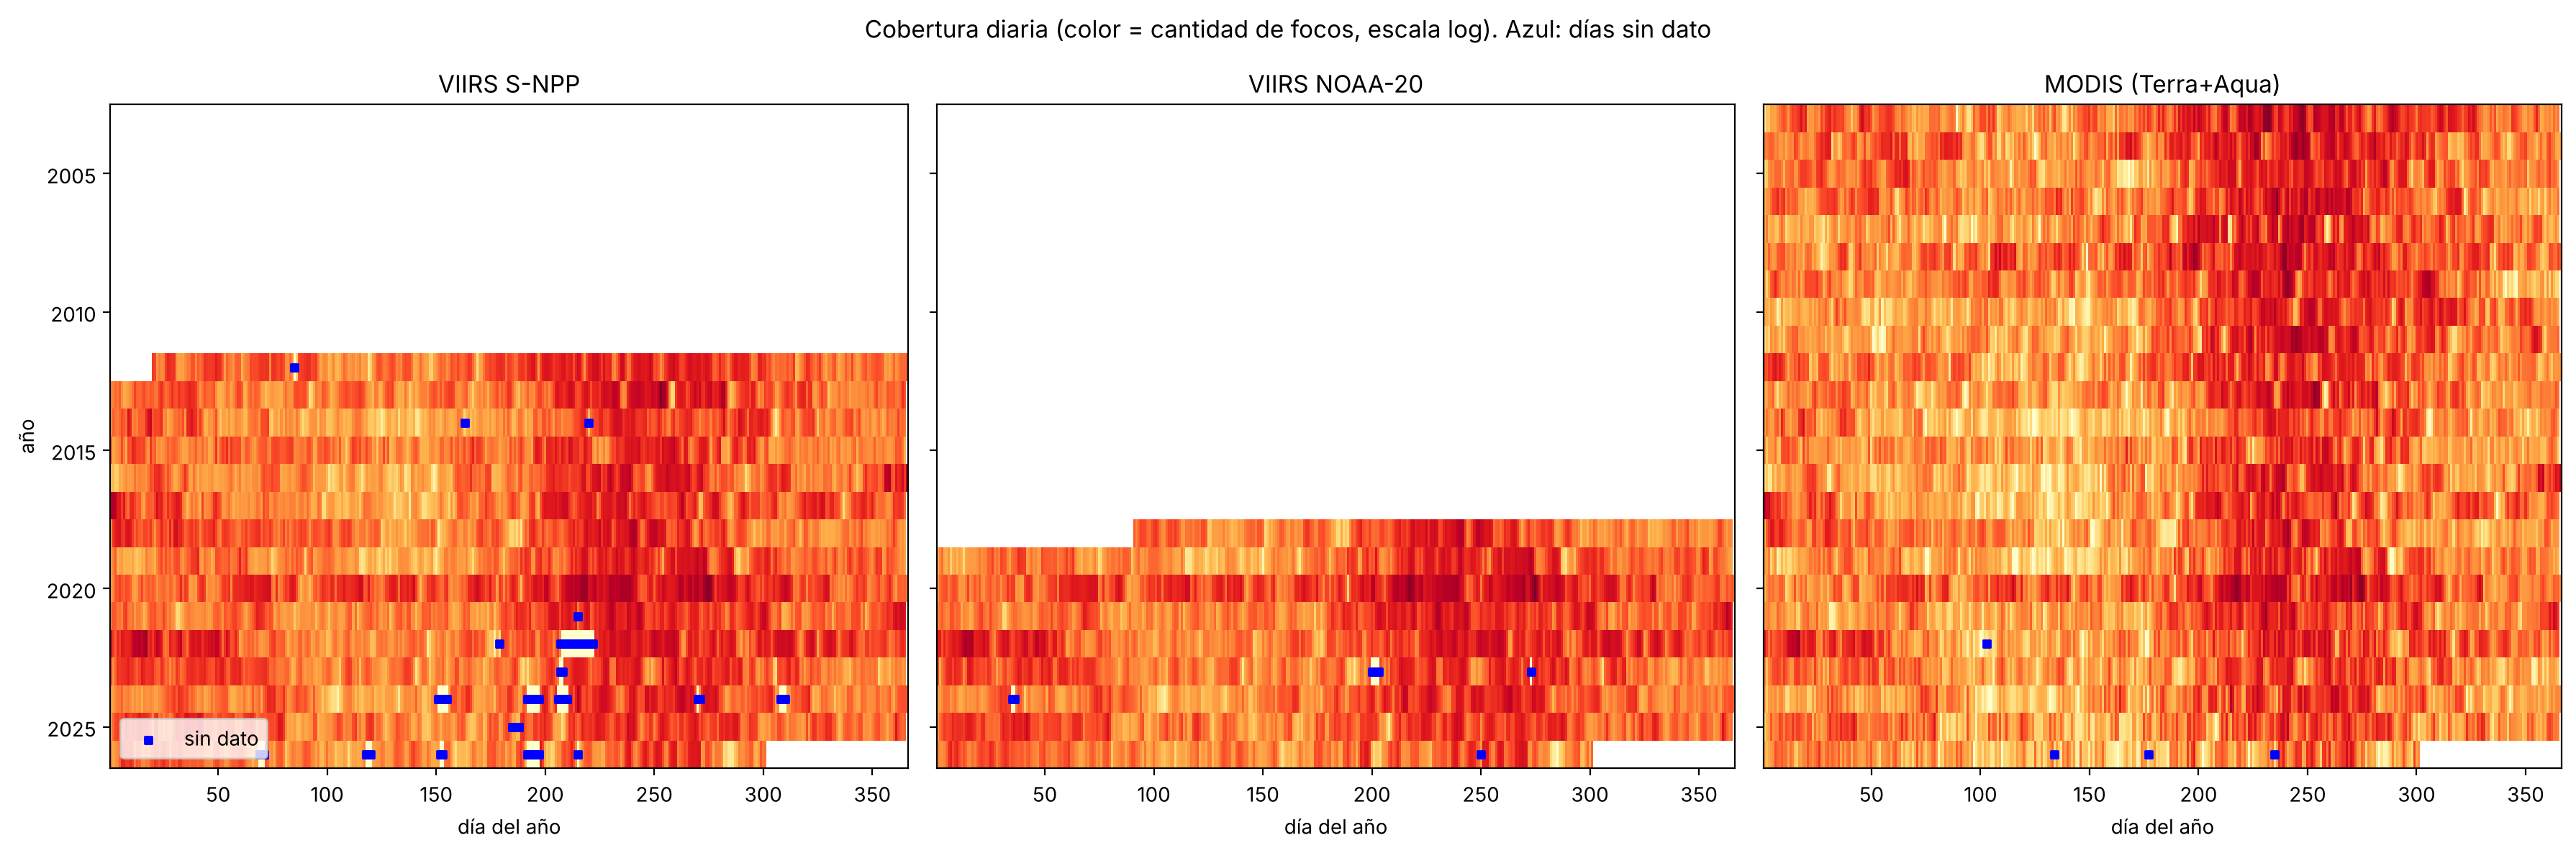

In [6]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# Calendario de cobertura: cada fila es un año, cada columna un día; en rojo, los días sin dato
fuentes_cal = [f for f in ["viirs", "n20", "modis"] if activo[f].any()]
fig, ejes = plt.subplots(1, len(fuentes_cal), figsize=(6 * len(fuentes_cal), 6), sharey=True)
ejes = np.atleast_1d(ejes)
for ax, f in zip(ejes, fuentes_cal):
    t = pd.DataFrame({"v": np.log1p(nac[f]).where(activo[f]), "anio": nac.index.year, "doy": nac.index.dayofyear})
    img = t.pivot_table(index="anio", columns="doy", values="v")
    ax.imshow(img, aspect="auto", cmap="YlOrRd", extent=[0.5, 366.5, img.index.max() + .5, img.index.min() - .5])
    h = nac.index[huecos[f]]
    ax.scatter(h.dayofyear, h.year, s=12, c="blue", marker="s", label="sin dato")
    ax.set_title(NOMBRE_FUENTE[f]); ax.set_xlabel("día del año")
ejes[0].set_ylabel("año"); ejes[0].legend(loc="lower left")
plt.suptitle("Cobertura diaria (color = cantidad de focos, escala log). Azul: días sin dato"); plt.tight_layout(); plt.show()

Duplicados entre partes del archivo: 0


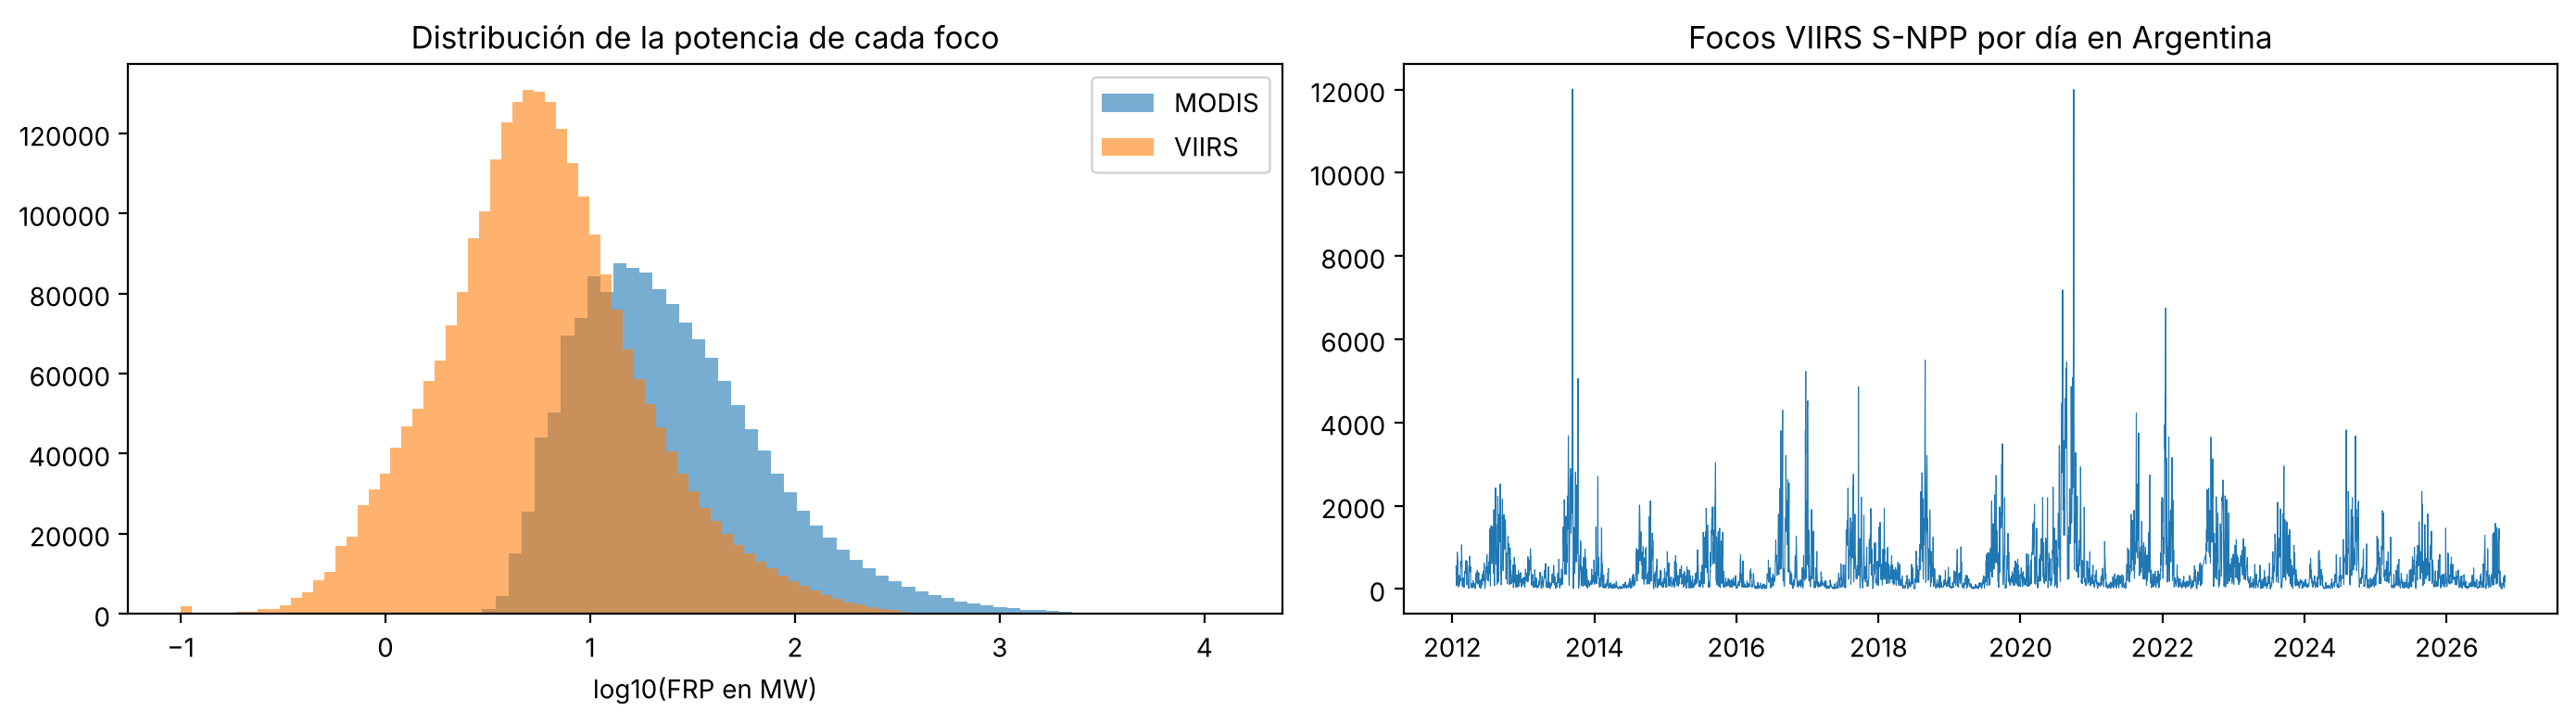

Los 10 focos más potentes (FRP):


,fecha,sensor,satelite,region,lat,lon,frp
638654,2010-11-18,MODIS,Terra,Gran Chaco,-26.13,-63.81,"13,294.50"
638636,2010-11-18,MODIS,Terra,Gran Chaco,-26.13,-63.80,"13,292.80"
638634,2010-11-18,MODIS,Terra,Gran Chaco,-26.14,-63.81,"10,680.10"
855988,2014-10-09,MODIS,Aqua,Gran Chaco,-24.16,-63.91,"10,647.90"
638652,2010-11-18,MODIS,Terra,Gran Chaco,-26.15,-63.81,"9,851.50"
1242505,2021-08-19,MODIS,Terra,Gran Chaco,-24.52,-61.10,"9,399.60"
1242495,2021-08-19,MODIS,Terra,Gran Chaco,-24.53,-61.10,"9,393.90"
1242506,2021-08-19,MODIS,Terra,Gran Chaco,-24.53,-61.07,"9,322.70"
986361,2017-08-25,MODIS,Aqua,Gran Chaco,-24.55,-60.68,"8,887.70"
986354,2017-08-25,MODIS,Aqua,Gran Chaco,-24.54,-60.67,"8,473.90"


Ningún día de 5,334 supera el umbral de valor atípico (z robusto > 3,5, en escala log): los días con más focos son extremos, pero coherentes con la temporada de quemas. Se conservan todos.
Los 10 días con más focos VIIRS:


,focos VIIRS,región con más focos
2013-09-10,"12,016.00",Gran Chaco
2020-10-01,"12,002.00",Gran Chaco
2020-09-30,"8,281.00",Gran Chaco
2020-08-05,"7,184.00",Resto del país
2020-10-02,"7,143.00",Gran Chaco
2020-08-04,"6,890.00",Gran Chaco
2022-01-17,"6,751.00",Resto del país
2013-09-11,"6,263.00",Gran Chaco
2020-08-06,"6,098.00",Gran Chaco
2018-08-29,"5,502.00",Gran Chaco


In [7]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# 4.4 Valores atípicos (se marcan, no se borran)
puntos = pd.concat(partes["puntos"], ignore_index=True)
n_dup_global = puntos.duplicated(["fecha", "hora_utc", "lat", "lon", "satelite"]).sum()
print(f"Duplicados entre partes del archivo: {n_dup_global:,}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for s, g in puntos.groupby("sensor"):
    ax[0].hist(np.log10(g.frp.clip(lower=0.1)), bins=80, alpha=.6, label=s)
ax[0].set_xlabel("log10(FRP en MW)"); ax[0].set_title("Distribución de la potencia de cada foco"); ax[0].legend()
diaria_v = nac.viirs.where(activo.viirs & ~huecos.viirs).dropna()
ax[1].plot(diaria_v.index, diaria_v, lw=.4); ax[1].set_title("Focos VIIRS S-NPP por día en Argentina")
plt.tight_layout(); plt.show()

print("Los 10 focos más potentes (FRP):")
display(puntos.nlargest(10, "frp")[["fecha", "sensor", "satelite", "region", "lat", "lon", "frp"]])

# Días atípicos: regla robusta (mediana y desvío absoluto mediano, en escala log)
lv = np.log1p(diaria_v)
z = 0.6745 * (lv - lv.median()) / (lv - lv.median()).abs().median()
atipicos = diaria_v[z > 3.5]
reg_top = (diario[diario.fuente == "viirs"].pivot_table(index="fecha", columns="region", values="focos").idxmax(axis=1))
top = pd.DataFrame({"focos VIIRS": diaria_v.nlargest(10)}).assign(
    **{"región con más focos": lambda d: reg_top.reindex(d.index).values})
if len(atipicos):
    print(f"Días con actividad extrema (z robusto > 3,5): {len(atipicos)} de {len(diaria_v):,}. Se conservan: son eventos reales.")
else:
    print(f"Ningún día de {len(diaria_v):,} supera el umbral de valor atípico (z robusto > 3,5, en escala log): "
          "los días con más focos son extremos, pero coherentes con la temporada de quemas. Se conservan todos.")
print("Los 10 días con más focos VIIRS:")
display(top)

Niveles de confianza (antes del filtro de confianza):


,MODIS (Terra+Aqua),VIIRS NOAA-20,VIIRS S-NPP
confidence,,,
nominal (30–79),1008552,0,0
alta (≥80),487047,0,0
baja (<30),66829,0,0
nominal (n),0,1473748,2393829
baja (l),0,165578,255589
alta (h),0,125699,231991


Proporción de focos de día (D) y de noche (N), en %:


daynight,D,N
MODIS (Terra+Aqua),86.60,13.40
VIIRS NOAA-20,73.20,26.80
VIIRS S-NPP,72.60,27.40


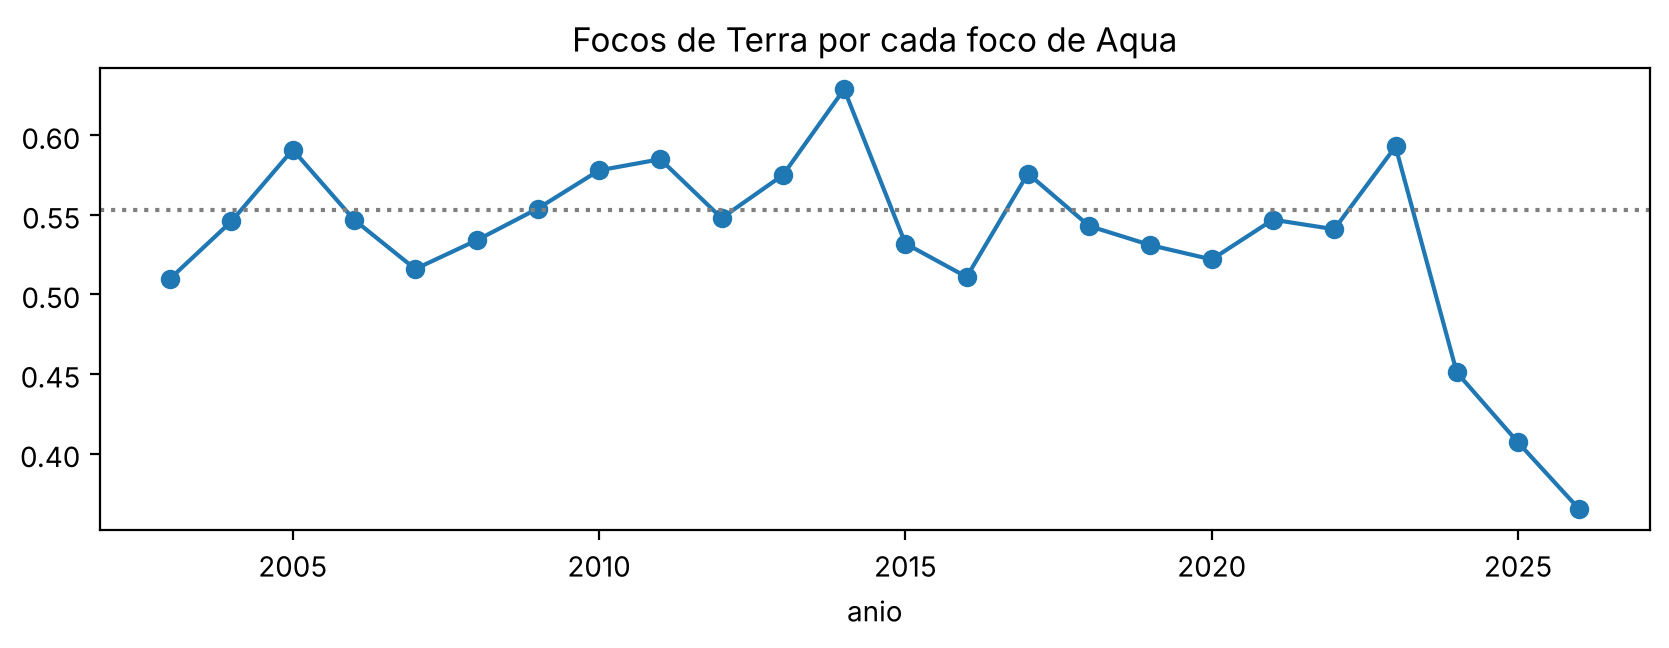

Terra cambió de órbita en los últimos años y detecta menos: por eso conviene armonizar con MODIS completo (Terra+Aqua).


In [8]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# 4.5 Confianza, día/noche y Terra/Aqua
conf = pd.concat(confianza, axis=1).T.groupby(level=0).sum().T
conf.columns = [NOMBRE_FUENTE[c] for c in conf.columns]
print("Niveles de confianza (antes del filtro de confianza):")
display(conf.fillna(0).astype(int))
if diaynoche:
    dn = pd.concat(diaynoche, axis=1).T.groupby(level=0).sum()
    dn.index = [NOMBRE_FUENTE[c] for c in dn.index]
    print("Proporción de focos de día (D) y de noche (N), en %:")
    display((100 * dn.div(dn.sum(axis=1), axis=0)).round(1))

ta = (terra_aqua.get("Terra") / terra_aqua.get("Aqua")).round(3)
ax = ta.plot(marker="o", figsize=(10, 3), title="Focos de Terra por cada foco de Aqua")
ax.axhline(ta.loc[2003:2019].mean(), color="gray", ls=":"); plt.show()
print("Terra cambió de órbita en los últimos años y detecta menos: por eso conviene armonizar con MODIS completo (Terra+Aqua).")

## 5. NOAA-20 vs S-NPP: calibración para rellenar los días sin dato

NOAA-20 lleva el **mismo instrumento** que S-NPP (VIIRS) y pasa unos 50 minutos después. Se calcula cuántos focos de S-NPP
equivalen a uno de NOAA-20 **en cada región y para cada medida**, usando solo los días en que los dos funcionaron.

**Validación:** se calibra con 2018–2021 y se mide el error con 2022–2025, años que la calibración no vio.

**Uso:** en los días sin dato de S-NPP se usa NOAA-20 × factor. Si NOAA-20 tampoco tiene dato (por ejemplo antes de 2018),
se usa MODIS convertido con el factor fijo de la región. Cada valor rellenado queda **marcado** en los resultados.

Calibración NOAA-20 → S-NPP y validación con 2022–2025:


,S-NPP / NOAA-20 (país),error mensual medio %,error total 2022–2025 %,correlación diaria
medida,,,,
Focos,1.03,3.87,-1.21,0.96
Días con fuego,0.98,2.23,-0.08,0.98
"Energía (FRP, MW)",1.03,7.60,-3.18,0.93


Factores por región (focos):


Gran Chaco           1.03
Delta del Paraná     1.05
Sierras de Córdoba   1.07
Corrientes e Iberá   1.02
Patagonia andina     1.03
Resto del país       1.02
Name: S-NPP por cada foco NOAA-20, dtype: float64

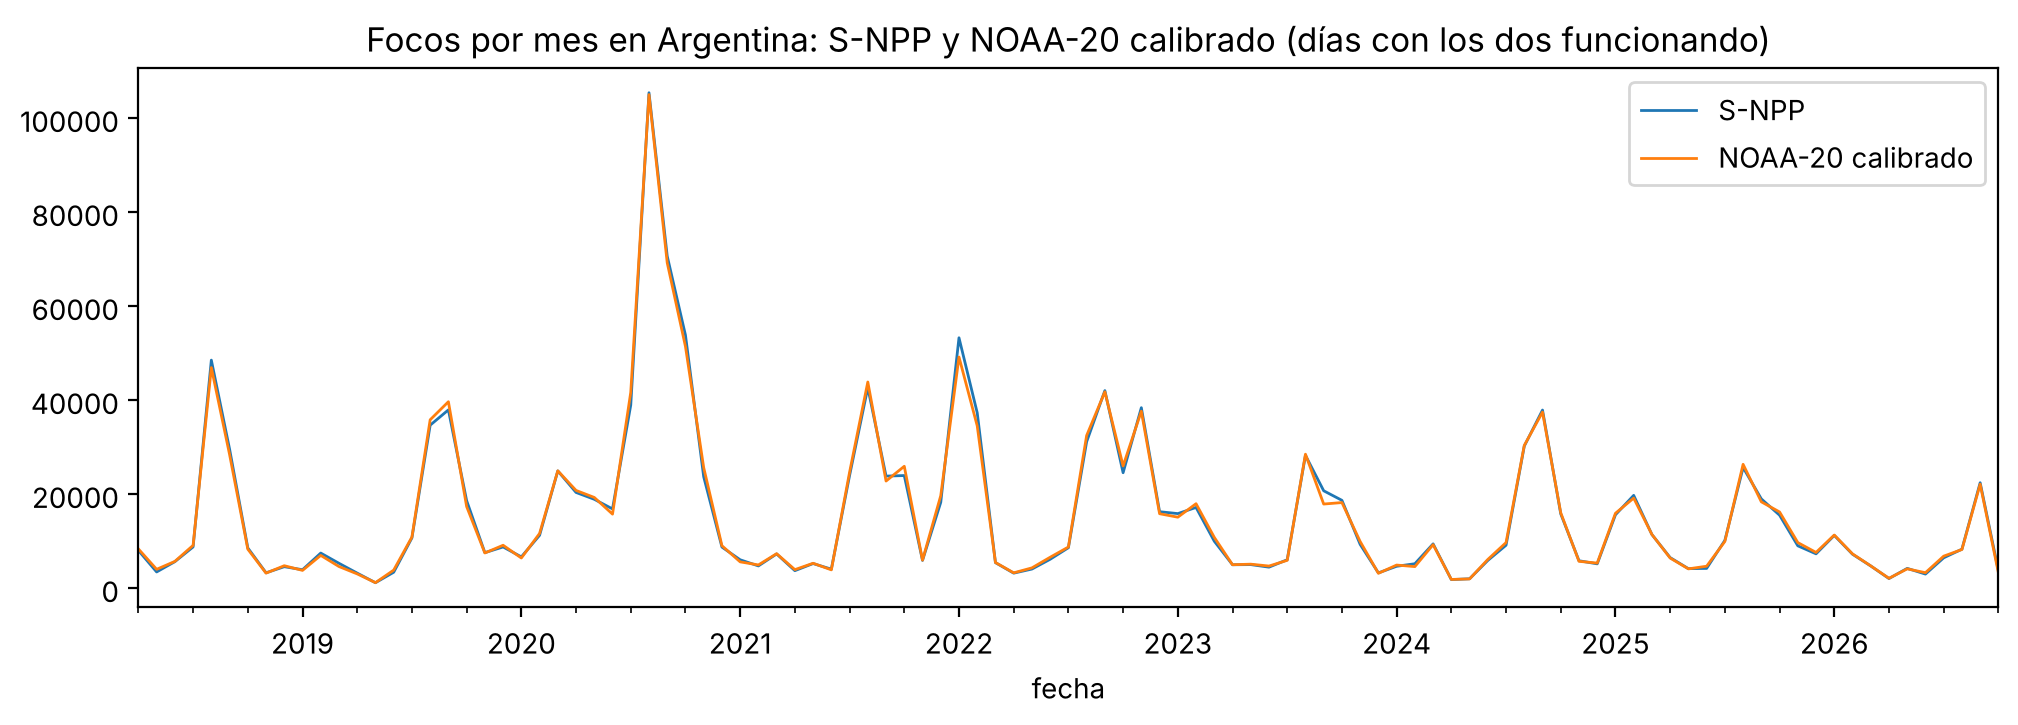

In [9]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# Tablas diarias por región para cada medida: columnas modis, viirs, n20
def tabla_diaria(m):
    t = (diario.pivot_table(index=["region", "fecha"], columns="fuente", values=m, aggfunc="sum")
         .reindex(pd.MultiIndex.from_product([REGIONES_MODELO, dias_todos], names=["region", "fecha"])).fillna(0))
    for f in ["modis", "viirs", "n20"]:
        if f not in t:
            t[f] = 0.0
    return t.reset_index()

diarias = {m: tabla_diaria(m) for m in MEDIDAS}
f_huecos = huecos.add_prefix("hueco_").assign(sin_dato_viirs=sin_dato_viirs, par=dia_valido_par,
                                              n20_activo=activo.n20)
for m in MEDIDAS:
    diarias[m] = diarias[m].merge(f_huecos, left_on="fecha", right_index=True)

def factor_region(d, num, den):
    "Factor num/den por región; si una región no tiene datos se usa el del país (punto 12, sin divisiones por cero)."
    s = d.groupby("region")[[num, den]].sum()
    pais = s[num].sum() / s[den].sum() if s[den].sum() > 0 else np.nan
    k = (s[num] / s[den].where(s[den] > 0)).reindex(REGIONES_MODELO)
    if k.isna().any():
        print(f"   ⚠️ Sin datos para {list(k[k.isna()].index)}: se usa el factor del país ({pais:.3f}).")
    return k.fillna(pais).to_dict()

K_N20, validacion_n20 = {}, []
if HAY_N20:
    for m in MEDIDAS:
        d = diarias[m]
        ok = d[d.par & d.n20_activo & ~d.hueco_n20]
        K_N20[m] = factor_region(ok, "viirs", "n20")
        # validación: calibrar con 2018–2021, probar con 2022–2025 (totales mensuales del país)
        k_tr = factor_region(ok[ok.fecha.dt.year <= 2021], "viirs", "n20")
        te = ok[ok.fecha.dt.year.isin(ANIOS_TEST)].assign(est=lambda x: x.n20 * x.region.map(k_tr))
        mens = te.groupby([te.fecha.dt.year, te.fecha.dt.month])[["viirs", "est"]].sum()
        validacion_n20.append({"medida": NOMBRE_MEDIDA[m],
                               "S-NPP / NOAA-20 (país)": ok.viirs.sum() / ok.n20.sum(),
                               "error mensual medio %": 100 * ((mens.est - mens.viirs).abs() / mens.viirs.where(mens.viirs > 0)).mean(),
                               "error total 2022–2025 %": 100 * (mens.est.sum() / mens.viirs.sum() - 1),
                               "correlación diaria": np.corrcoef(ok.groupby("fecha").viirs.sum(), ok.groupby("fecha").n20.sum())[0, 1]})
    validacion_n20 = pd.DataFrame(validacion_n20).set_index("medida")
    print("Calibración NOAA-20 → S-NPP y validación con 2022–2025:")
    display(validacion_n20.round(3))
    print("Factores por región (focos):")
    display(pd.Series(K_N20["focos"], name="S-NPP por cada foco NOAA-20").round(3))

    d = diarias["focos"]
    mens = (d[d.par & d.n20_activo & ~d.hueco_n20].assign(n20k=lambda x: x.n20 * x.region.map(K_N20["focos"]))
            .groupby(pd.Grouper(key="fecha", freq="MS"))[["viirs", "n20k"]].sum())
    ax = mens.rename(columns={"viirs": "S-NPP", "n20k": "NOAA-20 calibrado"}).plot(figsize=(12, 3.5), lw=1)
    ax.set_title("Focos por mes en Argentina: S-NPP y NOAA-20 calibrado (días con los dos funcionando)"); plt.show()
else:
    print("Sin datos de NOAA-20: se omite esta sección.")

## 6. Tres formas de medir, por región y mes

| Medida | Qué cuenta | Por qué |
|---|---|---|
| **Focos** | Cantidad de detecciones | Es la medida habitual, pero VIIRS divide cada incendio en más píxeles |
| **Días con fuego** | Pares (celda de 25 km, día) con al menos un foco | Un incendio vale lo mismo aunque tenga 1 o 5 píxeles |
| **Energía (FRP)** | Suma de la potencia radiativa, en MW | Mide energía, no cantidad de píxeles |

**Cómo se tratan los días sin dato (punto 5):**
- **Para entrenar y evaluar** los métodos se comparan MODIS y VIIRS **solo en los días en que los dos funcionaron**, y se
  llevan a mes completo con una regla de tres. Un mes con menos de 20 días válidos se descarta. Nunca se entrena con
  datos rellenados: sería circular.
- **Para la serie publicada**, a lo observado por S-NPP se le suma el **relleno** de los días sin dato (NOAA-20 o MODIS),
  y se guarda aparte cuánto se rellenó.

In [10]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
fin_mes = FECHA_FIN.year * 12 + FECHA_FIN.month
indice = pd.MultiIndex.from_product([REGIONES_MODELO, range(ANIO_INICIO_MODIS, ANIO_FIN + 1), range(1, 13)],
                                    names=["region", "anio", "mes"])
FACTOR_MODIS = {}     # factor fijo VIIRS/MODIS por región y medida (para rellenar sin NOAA-20)

def armar(m):
    d = diarias[m].copy()
    d["anio"], d["mes"] = d.fecha.dt.year, d.fecha.dt.month
    FACTOR_MODIS[m] = factor_region(d[d.par & (d.anio <= 2025)], "viirs", "modis")
    # relleno de los días sin dato de S-NPP
    usa_n20 = d.sin_dato_viirs & d.n20_activo & ~d.hueco_n20
    d["relleno"] = 0.0
    if HAY_N20:
        d.loc[usa_n20, "relleno"] = d.n20[usa_n20] * d.region[usa_n20].map(K_N20[m])
    usa_modis = d.sin_dato_viirs & ~usa_n20 & ~d.hueco_modis
    d.loc[usa_modis, "relleno"] = d.modis[usa_modis] * d.region[usa_modis].map(FACTOR_MODIS[m])
    d["viirs_obs"] = d.viirs.where(~d.sin_dato_viirs & (d.fecha >= INICIO_VIIRS), 0)
    d["modis_par"], d["viirs_par"] = d.modis.where(d.par, 0), d.viirs.where(d.par, 0)
    g = d.groupby(["region", "anio", "mes"])
    t = pd.DataFrame({"modis": g.modis.sum(), "viirs": g.viirs_obs.sum(), "relleno": g.relleno.sum(),
                      "modis_par": g.modis_par.sum(), "viirs_par": g.viirs_par.sum(),
                      "dias_mes": g.size(), "dias_par": g.par.sum(), "dias_sin_dato": g.sin_dato_viirs.sum()})
    t = t.reindex(indice).reset_index()
    # mes completo equivalente (regla de tres) y descarte de meses con pocos días válidos
    escala = t.dias_mes / t.dias_par.where(t.dias_par >= MIN_DIAS_PAR)
    t["modis_par"], t["viirs_par"] = t.modis_par * escala, t.viirs_par * escala
    t.loc[t.anio < ANIO_INICIO_VIIRS, ["viirs", "relleno"]] = np.nan
    futuro = t.anio * 12 + t.mes > fin_mes
    t.loc[futuro, ["modis", "viirs", "relleno", "modis_par", "viirs_par"]] = np.nan
    return t

tablas = {m: armar(m) for m in MEDIDAS}

# Tablas «como antes» (días sin dato contados como cero), para mostrar el efecto de la corrección
def armar_antes(m):
    d = diarias[m]
    g = d.groupby([d.region, d.fecha.dt.year.rename("anio"), d.fecha.dt.month.rename("mes")])
    t = pd.DataFrame({"modis_par": g.modis.sum(), "viirs_par": g.viirs.sum()}).reindex(indice).reset_index()
    t.loc[t.anio < ANIO_INICIO_VIIRS, "viirs_par"] = np.nan
    t.loc[t.anio * 12 + t.mes > fin_mes, ["modis_par", "viirs_par"]] = np.nan
    return t

tablas_antes = {m: armar_antes(m) for m in MEDIDAS}

t = tablas["focos"]
excl = t[(t.anio.between(2012, 2025)) & (t.region == RESTO) & t.viirs_par.isna()]
print(f"Meses 2012–2025 descartados para entrenar/evaluar por tener menos de {MIN_DIAS_PAR} días válidos: "
      f"{len(excl)} → {', '.join(f'{a}-{m:02d}' for a, m in zip(excl.anio, excl.mes))}")
rell = t[t.dias_sin_dato > 0].groupby(["anio", "mes"]).agg(dias=("dias_sin_dato", "first"), relleno=("relleno", "sum"))
print(f"Meses con días rellenados: {len(rell)}. Focos rellenados en total: {rell.relleno.sum():,.0f}")
display(rell.sort_values("relleno", ascending=False).head(8).round(0))

Meses 2012–2025 descartados para entrenar/evaluar por tener menos de 20 días válidos: 1 → 2012-01
Meses con días rellenados: 20. Focos rellenados en total: 39,635


dias   relleno
anio mes                
2012 1   19.00 14,531.00
2024 7   11.00  6,108.00
2022 8   10.00  4,749.00
     7    6.00  3,741.00
2026 7    6.00  3,125.00
2021 8    1.00  1,324.00
2025 7    3.00  1,074.00
2024 9    2.00  1,036.00

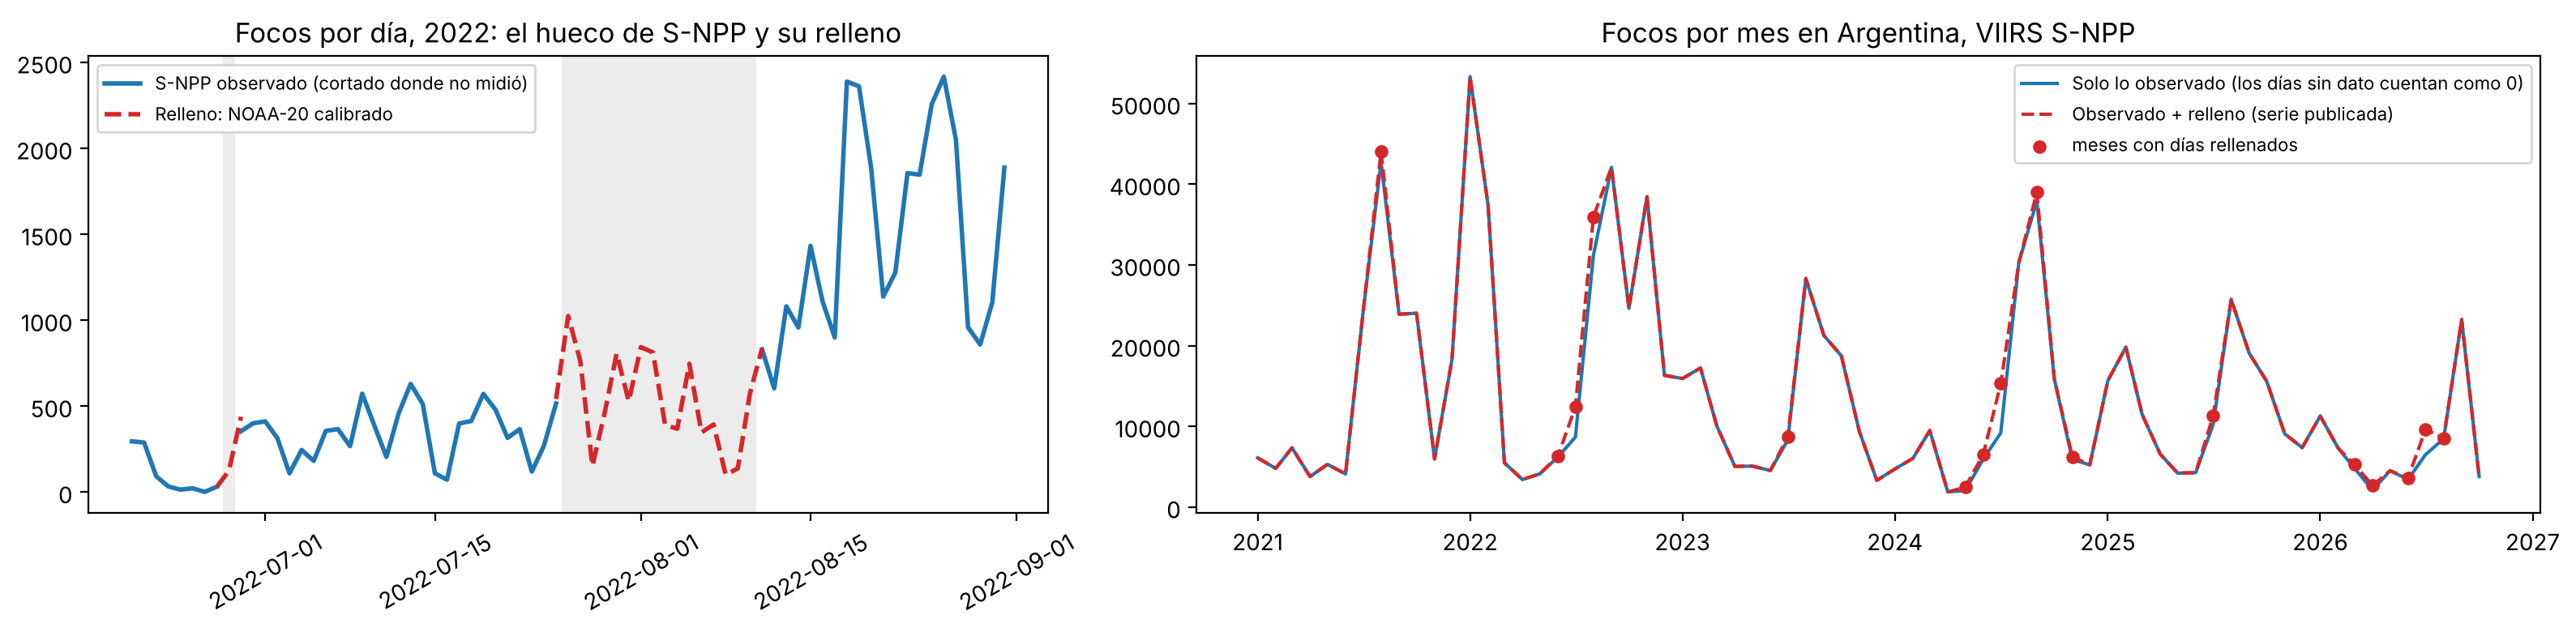

In [11]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# Cómo se ve un hueco y su relleno: julio–agosto de 2022 (S-NPP apagado 16 días)
d = diarias["focos"].groupby("fecha")[["viirs", "n20", "sin_dato_viirs"]].agg(
    {"viirs": "sum", "n20": "sum", "sin_dato_viirs": "first"})
ventana = d.loc["2022-06-20":"2022-08-31"]
k = K_N20_PAIS if HAY_N20 else np.nan
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].plot(ventana.index, ventana.viirs.where(~ventana.sin_dato_viirs), "-", color="C0", lw=2,
           label="S-NPP observado (cortado donde no midió)")
if HAY_N20:
    ax[0].plot(ventana.index, (ventana.n20 * k).where(ventana.sin_dato_viirs | ventana.sin_dato_viirs.shift(1, fill_value=False)
                                                   | ventana.sin_dato_viirs.shift(-1, fill_value=False)),
               "--", color="C3", lw=2, label="Relleno: NOAA-20 calibrado")
for i in ventana.index[ventana.sin_dato_viirs]:
    ax[0].axvspan(i - pd.Timedelta("12h"), i + pd.Timedelta("12h"), color="gray", alpha=.15, lw=0)
ax[0].set_title("Focos por día, 2022: el hueco de S-NPP y su relleno"); ax[0].legend(fontsize=8)
ax[0].tick_params(axis="x", rotation=30)

t = tablas["focos"].groupby(["anio", "mes"])[["viirs", "relleno", "dias_sin_dato"]].agg(
    {"viirs": "sum", "relleno": "sum", "dias_sin_dato": "first"}).reset_index()
t = t[(t.anio >= 2021) & (t.anio * 12 + t.mes <= fin_mes)]
x = pd.to_datetime(dict(year=t.anio, month=t.mes, day=1))
ax[1].plot(x, t.viirs, "-", color="C0", label="Solo lo observado (los días sin dato cuentan como 0)")
ax[1].plot(x, t.viirs + t.relleno, "--", color="C3", label="Observado + relleno (serie publicada)")
con = t.dias_sin_dato > 0
ax[1].scatter(x[con], (t.viirs + t.relleno)[con], color="C3", zorder=3, s=25, label="meses con días rellenados")
ax[1].set_title("Focos por mes en Argentina, VIIRS S-NPP"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. El problema: el salto falso de 2012

Si se pegan MODIS (hasta 2011) y VIIRS (desde 2012), parece que el fuego se multiplicó en 2012.
Es el cambio de sensor, no un cambio real.

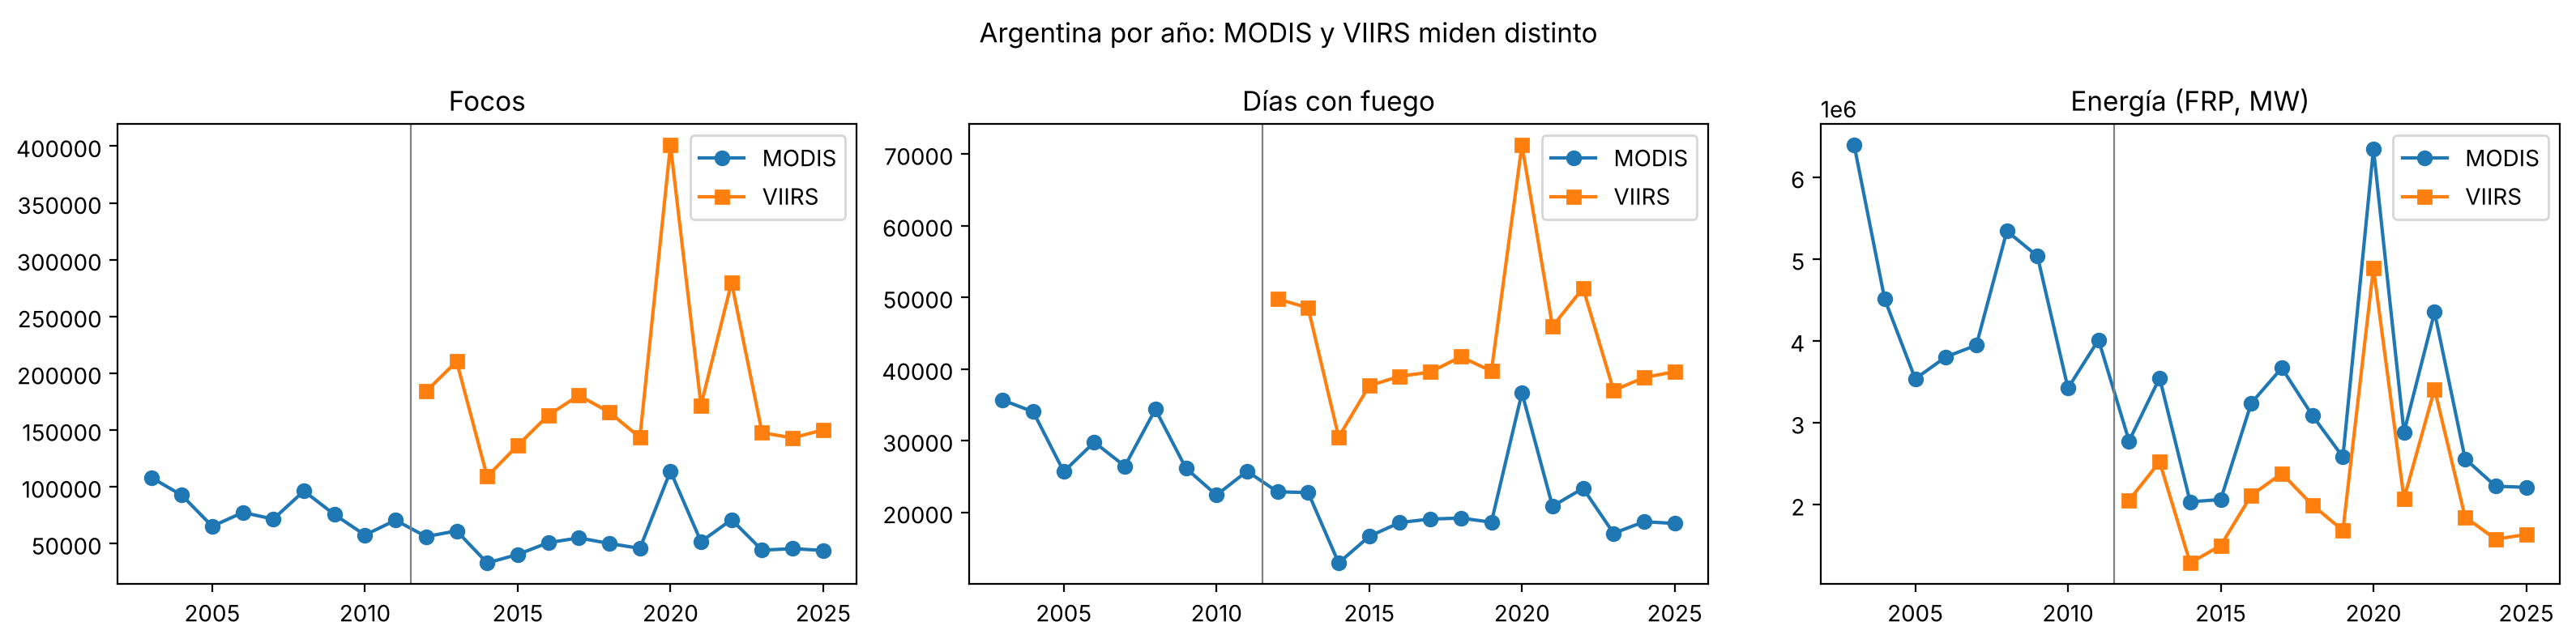

,VIIRS/MODIS promedio,mínimo anual,máximo anual,variación (CV %)
medida,,,,
Focos,3.36,3.13,3.91,5.75
Días con fuego,2.15,1.94,2.36,4.44
"Energía (FRP, MW)",0.70,0.63,0.77,6.80


In [12]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(ejes, MEDIDAS):
    t = tablas[m][tablas[m].anio <= 2025]
    ax.plot(t.groupby("anio").modis.sum(min_count=1), "o-", label="MODIS")
    ax.plot((t.viirs + t.relleno).groupby(t.anio).sum(min_count=1), "s-", label="VIIRS")
    ax.axvline(2011.5, color="gray", lw=.8)
    ax.set_title(NOMBRE_MEDIDA[m]); ax.legend()
plt.suptitle("Argentina por año: MODIS y VIIRS miden distinto"); plt.tight_layout(); plt.show()

resumen = []
for m, t in tablas.items():
    c = t[t.anio.between(2012, 2025)].groupby("anio")[["modis_par", "viirs_par"]].sum()
    r = c.viirs_par / c.modis_par
    resumen.append({"medida": NOMBRE_MEDIDA[m], "VIIRS/MODIS promedio": r.mean(),
                    "mínimo anual": r.min(), "máximo anual": r.max(), "variación (CV %)": 100 * r.std() / r.mean()})
pd.DataFrame(resumen).set_index("medida")

## 8. Comparación de métodos de armonización

**Objetivo:** estimar cuánto habría medido VIIRS a partir de lo que midió MODIS, en cada región y mes.

**Validación honesta:** cada método aprende con **2012–2021** y se evalúa con **2022–2025**, años que no vio.
Todo, incluida la corrección de sesgo κ, se calcula **solo con 2012–2021**: el sesgo que se informa es fuera de muestra (punto 7).

| # | Método | Fórmula / idea | Complejidad |
|---|---|---|---|
| 1 | Factor fijo por región | V = k · M | Muy baja |
| 2 | Regresión logarítmica por región y mes | log(1+V) = a + b·log(1+M) + c·sen(mes) + d·cos(mes) | Baja |
| 3 | Mapeo de cuantiles por región | V = F_V⁻¹(F_M(M)): se emparejan percentiles | Media |
| 4 | Random Forest | Promedio de 300 árboles de decisión | Alta |

En los métodos 2 y 4 se corrige el **sesgo de volver de la escala logarítmica** (desigualdad de Jensen) con un factor κ.
En el método 3, si un mes supera todo lo visto en el entrenamiento, se extrapola con el factor de la región,
con un tope de 5 veces ese factor (punto 6).

**Métricas (sobre el período de prueba):**
- **MAE:** error promedio por región y mes. Más bajo es mejor. Se informa con su **intervalo de confianza del 95 %**
  (bootstrap por bloques de meses, 2.000 repeticiones: punto 10).
- **R² (log):** qué parte de la variación explica (1 = perfecto).
- **Sesgo total:** cuánto se pasa (+) o se queda corto (−) en el total del período.
- **Peor año (país):** el mayor error en el total anual de Argentina.

In [13]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

def estacion(df):
    return np.c_[np.sin(2 * np.pi * df.mes / 12), np.cos(2 * np.pi * df.mes / 12)]

def chequear_regiones(df, conocidas):
    nuevas = set(df.region) - set(conocidas)
    assert not nuevas, f"Regiones que el modelo no vio al entrenar: {nuevas}"     # punto 13

def kappa_seguro(real, predicho):
    s = predicho.sum()
    return real.sum() / s if s > 0 else 1.0                                        # punto 12

# ---------- 1. Factor fijo por región
def ajustar_factor(tr):
    return factor_region(tr, "viirs", "modis")

def predecir_factor(k, df):
    chequear_regiones(df, k)
    return df.modis * df.region.map(k)

# ---------- 2. Regresión logarítmica por región y mes (con corrección de sesgo)
def ajustar_regresion(tr):
    modelos = {}
    for r, sub in tr.groupby("region"):
        X = np.c_[np.log1p(sub.modis), estacion(sub)]
        lr = LinearRegression().fit(X, np.log1p(sub.viirs))
        modelos[r] = (lr, kappa_seguro(sub.viirs, np.expm1(lr.predict(X)).clip(0)))
    return modelos

def predecir_regresion(modelos, df):
    chequear_regiones(df, modelos)
    p = pd.Series(np.nan, index=df.index)
    for r, sub in df.groupby("region"):
        lr, kappa = modelos[r]
        p[sub.index] = np.expm1(lr.predict(np.c_[np.log1p(sub.modis), estacion(sub)])).clip(0) * kappa
    return p

# ---------- 3. Mapeo de cuantiles por región
EXTRAPOLADOS = {"n": 0}
def ajustar_cuantiles(tr):
    return {r: (np.sort(sub.modis.values), np.sort(sub.viirs.values), kappa_seguro(sub.viirs, sub.modis))
            for r, sub in tr.groupby("region")}

def predecir_cuantiles(q, df):
    chequear_regiones(df, q)
    p = pd.Series(np.nan, index=df.index)
    for r, sub in df.groupby("region"):
        m_ord, v_ord, k = q[r]
        x = sub.modis.values
        prob = (np.searchsorted(m_ord, x, "left") + np.searchsorted(m_ord, x, "right")) / (2 * len(m_ord))
        y = np.quantile(v_ord, np.clip(prob, 0, 1))
        mas_alto = x > m_ord[-1]                       # más alto que todo lo visto: se extrapola con el factor
        y[mas_alto] = np.minimum(v_ord[-1] + (x[mas_alto] - m_ord[-1]) * k, 5 * k * x[mas_alto])
        EXTRAPOLADOS["n"] += int(mas_alto.sum())
        p[sub.index] = y
    return p

# ---------- 4. Random Forest (corrección de sesgo con predicciones "out of bag")
def X_rf(df):
    X = pd.DataFrame({"log_modis": np.log1p(df.modis)}, index=df.index)
    X[["mes_sen", "mes_cos"]] = estacion(df)
    for r in REGIONES_MODELO:
        X["reg_" + r] = (df.region == r).astype(int)
    return X

def ajustar_rf(tr):
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, oob_score=True,
                               random_state=42, n_jobs=-1).fit(X_rf(tr), np.log1p(tr.viirs))
    return rf, kappa_seguro(tr.viirs, np.expm1(rf.oob_prediction_).clip(0))

def predecir_rf(m, df):
    rf, kappa = m
    return pd.Series(np.expm1(rf.predict(X_rf(df))).clip(0) * kappa, index=df.index)

METODOS = {   # en orden de complejidad: importa para la regla de elección
    "Factor fijo por región":         (ajustar_factor, predecir_factor),
    "Regresión log por región y mes": (ajustar_regresion, predecir_regresion),
    "Mapeo de cuantiles":             (ajustar_cuantiles, predecir_cuantiles),
    "Random Forest":                  (ajustar_rf, predecir_rf),
}
B_BOOT = 2000
rng = np.random.default_rng(42)

def datos_par(t):
    "Meses 2012–2025 con datos válidos de los dos sensores (columnas modis/viirs = días en común)."
    c = t[t.anio.between(2012, 2025) & t.viirs_par.notna()]
    return c[["region", "anio", "mes", "modis_par", "viirs_par"]].rename(columns={"modis_par": "modis", "viirs_par": "viirs"})

def evaluar(t, boot=True):
    comun = datos_par(t)
    tr, te = comun[comun.anio.isin(ANIOS_ENTRENAMIENTO)], comun[comun.anio.isin(ANIOS_TEST)]
    filas, anual, errores = [], {"Real": te.groupby("anio").viirs.sum()}, {}
    for nombre, (ajustar, predecir) in METODOS.items():
        p = predecir(ajustar(tr), te)
        err_anual = 100 * (p.groupby(te.anio).sum() / te.groupby("anio").viirs.sum() - 1)
        filas.append({"método": nombre,
                      "MAE": (te.viirs - p).abs().mean(),
                      "R² (log)": r2_score(np.log1p(te.viirs), np.log1p(p)),
                      "Sesgo total %": 100 * (p.sum() / te.viirs.sum() - 1),
                      "Peor año (país) %": err_anual.abs().max()})
        anual[nombre] = p.groupby(te.anio).sum()
        errores[nombre] = (te.viirs - p).abs()
    res = pd.DataFrame(filas).set_index("método")
    boot_mae = None
    if boot:
        # bootstrap por bloques: se re-sortean meses completos (todas las regiones de ese mes juntas)
        bloque = (te.anio * 100 + te.mes).values
        ids, inv = np.unique(bloque, return_inverse=True)
        n_bloque = np.bincount(inv)
        muestras = rng.integers(0, len(ids), size=(B_BOOT, len(ids)))
        boot_mae = {}
        for nombre, err in errores.items():
            suma_b = np.bincount(inv, weights=err.values)
            boot_mae[nombre] = suma_b[muestras].sum(1) / n_bloque[muestras].sum(1)
        res["MAE IC95 bajo"] = [np.percentile(boot_mae[n], 2.5) for n in res.index]
        res["MAE IC95 alto"] = [np.percentile(boot_mae[n], 97.5) for n in res.index]
    return res, pd.DataFrame(anual), boot_mae

resultados, anual_test, boot = {}, {}, {}
for m, t in tablas.items():
    EXTRAPOLADOS["n"] = 0
    resultados[m], anual_test[m], boot[m] = evaluar(t)
    print(f"\n=== {NOMBRE_MEDIDA[m]} === (meses de prueba: {len(datos_par(t).query('anio in @ANIOS_TEST')) // len(REGIONES_MODELO)}; "
          f"extrapolaciones del método de cuantiles: {EXTRAPOLADOS['n']})")
    display(resultados[m].round(3))


=== Focos === (meses de prueba: 48; extrapolaciones del método de cuantiles: 2)


,MAE,R² (log),Sesgo total %,Peor año (país) %,MAE IC95 bajo,MAE IC95 alto
método,,,,,,
Factor fijo por región,391.03,0.95,-4.55,13.55,282.35,532.27
Regresión log por región y mes,370.22,0.97,-3.52,13.46,260.46,515.62
Mapeo de cuantiles,418.58,0.97,-7.49,17.70,295.60,571.87
Random Forest,413.86,0.98,-3.26,13.23,302.22,546.25



=== Días con fuego === (meses de prueba: 48; extrapolaciones del método de cuantiles: 2)


,MAE,R² (log),Sesgo total %,Peor año (país) %,MAE IC95 bajo,MAE IC95 alto
método,,,,,,
Factor fijo por región,83.19,0.94,-0.70,2.35,68.14,100.54
Regresión log por región y mes,62.45,0.98,1.15,4.89,51.33,74.69
Mapeo de cuantiles,56.67,0.98,1.45,4.29,47.15,67.20
Random Forest,62.33,0.98,1.94,4.09,50.67,74.39



=== Energía (FRP, MW) === (meses de prueba: 48; extrapolaciones del método de cuantiles: 3)


,MAE,R² (log),Sesgo total %,Peor año (país) %,MAE IC95 bajo,MAE IC95 alto
método,,,,,,
Factor fijo por región,"4,497.08",0.91,-1.93,5.54,"3,419.10","5,748.54"
Regresión log por región y mes,"4,214.82",0.92,-1.37,7.48,"3,057.03","5,656.05"
Mapeo de cuantiles,"4,891.17",0.95,-3.38,5.88,"3,481.13","6,487.12"
Random Forest,"4,752.65",0.95,-3.00,11.44,"3,458.13","6,332.24"


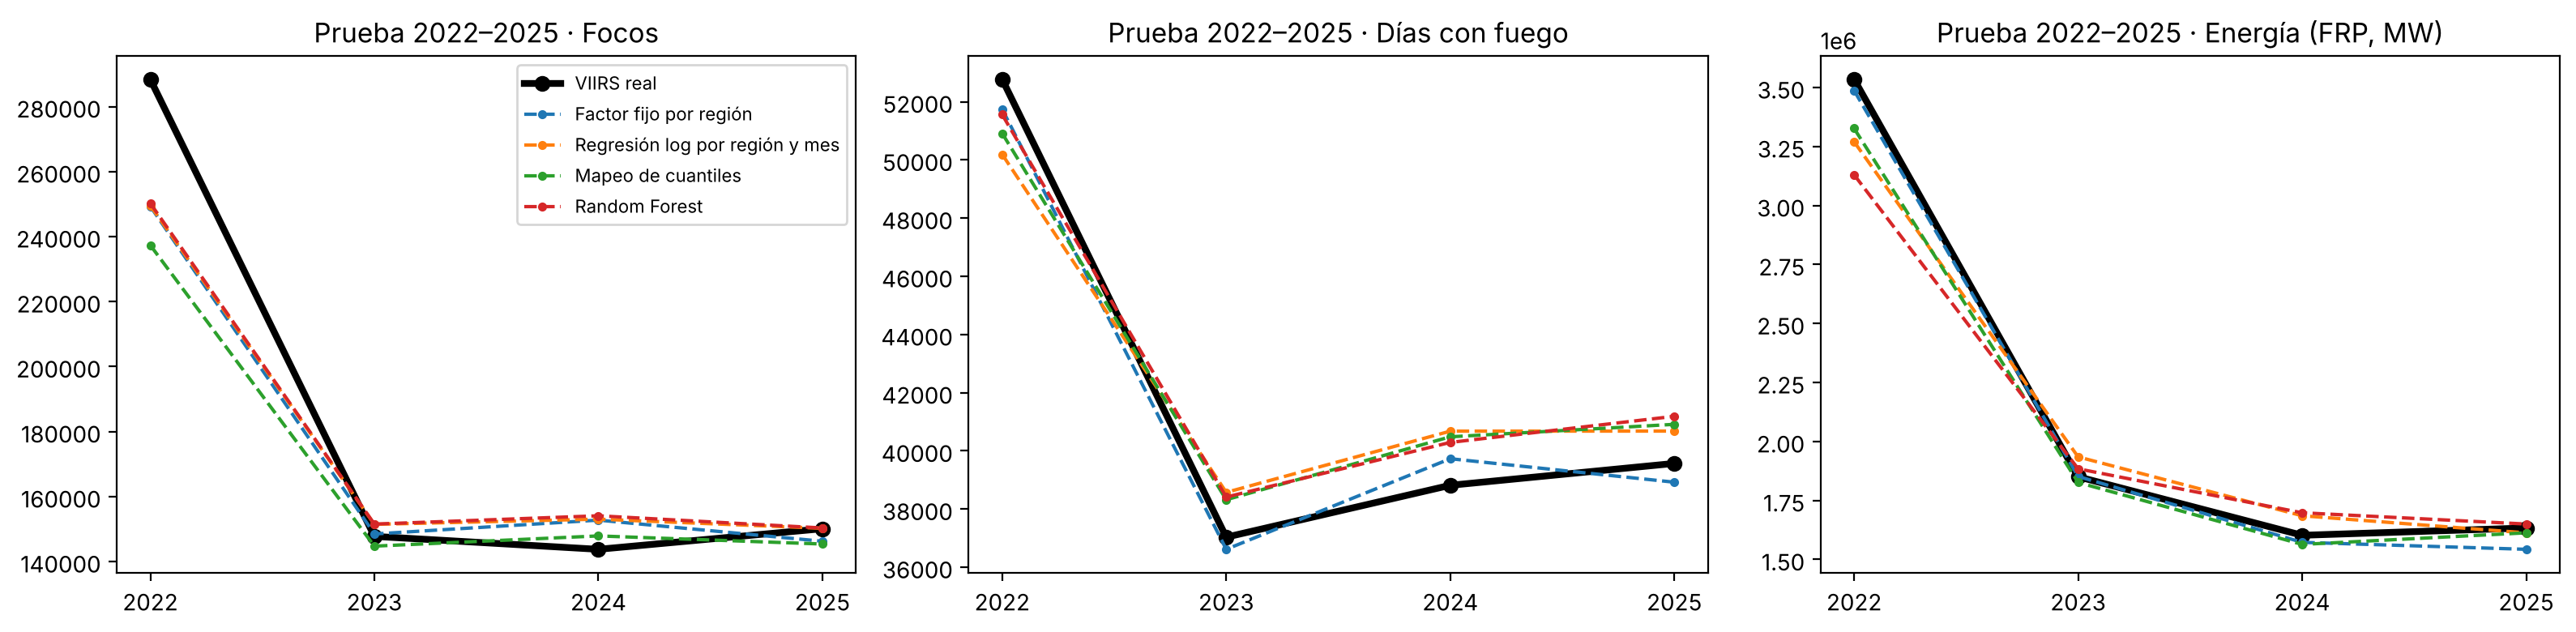

Efecto de no contar los días sin dato como «cero fuego» (prueba 2022–2025):


,medida,método,Sesgo % antes,Sesgo % después,Peor año % antes,Peor año % después
0,Focos,Factor fijo por región,-3.18,-4.55,12.37,13.55
1,Focos,Regresión log por región y mes,-2.03,-3.52,12.83,13.46
2,Días con fuego,Factor fijo por región,1.68,-0.70,9.35,2.35
3,Días con fuego,Regresión log por región y mes,4.12,1.15,12.67,4.89
4,"Energía (FRP, MW)",Factor fijo por región,-1.13,-1.93,5.69,5.54
5,"Energía (FRP, MW)",Regresión log por región y mes,-0.06,-1.37,9.63,7.48


In [14]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(ejes, MEDIDAS):
    d = anual_test[m]
    ax.plot(d.index, d["Real"], "k-o", lw=3, label="VIIRS real")
    for c in d.columns[1:]:
        ax.plot(d.index, d[c], "--", marker=".", label=c)
    ax.set_title(f"Prueba {ANIOS_TEST[0]}–{ANIOS_TEST[-1]} · {NOMBRE_MEDIDA[m]}"); ax.set_xticks(d.index)
ejes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# Antes y después de corregir los días sin dato (mismo método, mismos años de prueba)
filas = []
for m in MEDIDAS:
    antes, _, _ = evaluar(tablas_antes[m], boot=False)
    for metodo in ["Factor fijo por región", "Regresión log por región y mes"]:
        filas.append({"medida": NOMBRE_MEDIDA[m], "método": metodo,
                      "Sesgo % antes": antes.loc[metodo, "Sesgo total %"],
                      "Sesgo % después": resultados[m].loc[metodo, "Sesgo total %"],
                      "Peor año % antes": antes.loc[metodo, "Peor año (país) %"],
                      "Peor año % después": resultados[m].loc[metodo, "Peor año (país) %"]})
antes_despues = pd.DataFrame(filas)
print("Efecto de no contar los días sin dato como «cero fuego» (prueba 2022–2025):")
display(antes_despues.round(2))

## 9. Elección del método

**Regla (puntos 8, 10 y 11):** se elige el método **más simple** que cumpla las tres condiciones:
1. su MAE no supera en más de un **5 %** al del mejor;
2. su **sesgo total** está entre −10 % y +10 %;
3. su **peor año** tiene un error menor al **25 %**.

Así un modelo complejo solo gana si mejora de verdad, y no se elige un método «preciso en promedio» que se equivoca
mucho en un año o en el total. Además se informa si la diferencia con el mejor es **estadísticamente significativa**
(intervalo de confianza del 95 % de la diferencia de MAE, con bootstrap).

In [15]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
TOLERANCIA, MAX_SESGO, MAX_PEOR_ANIO = 0.05, 10.0, 25.0
REGLA = (f"Método más simple con MAE ≤ mejor × {1 + TOLERANCIA:.2f}, |sesgo| ≤ {MAX_SESGO:.0f} % "
         f"y peor año ≤ {MAX_PEOR_ANIO:.0f} % (prueba {ANIOS_TEST[0]}–{ANIOS_TEST[-1]}).")
elegido, justificacion, intervalos = {}, {}, {}
for m, res in resultados.items():
    mejor = res["MAE"].idxmin(); mejor_mae = res.loc[mejor, "MAE"]
    cumple = ((res["MAE"] <= mejor_mae * (1 + TOLERANCIA)) & (res["Sesgo total %"].abs() <= MAX_SESGO)
              & (res["Peor año (país) %"] <= MAX_PEOR_ANIO))
    if cumple.any():
        elegido[m] = cumple[cumple].index[0]          # el primero = el más simple (METODOS está ordenado)
        aviso = ""
    else:
        elegido[m] = mejor
        aviso = " ⚠️ Ningún método cumple las tres condiciones: se elige el de menor error."
    e = res.loc[elegido[m]]
    texto = (f"Se eligió «{elegido[m]}»: MAE {e['MAE']:,.1f} por región y mes "
             f"(IC 95 %: {e['MAE IC95 bajo']:,.1f}–{e['MAE IC95 alto']:,.1f}), sesgo total {e['Sesgo total %']:+.1f} % "
             f"y peor año {e['Peor año (país) %']:.1f} % en {ANIOS_TEST[0]}–{ANIOS_TEST[-1]}.{aviso} ")
    if elegido[m] == mejor:
        texto += "Es el de menor error."
        simple = list(METODOS)[0]
        if elegido[m] != simple:
            dif = 100 * (boot[m][simple] / boot[m][elegido[m]] - 1)
            lo, hi = np.percentile(dif, [2.5, 97.5])
            texto += (f" El más simple («{simple}») tuvo MAE {res.loc[simple, 'MAE']:,.1f}: "
                      f"{100 * (res.loc[simple, 'MAE'] / mejor_mae - 1):.1f} % más error (IC 95 %: {lo:+.1f} % a {hi:+.1f} %), "
                      f"por encima de la tolerancia del {100 * TOLERANCIA:.0f} %.")
    else:
        dif = 100 * (boot[m][elegido[m]] / boot[m][mejor] - 1)
        lo, hi = np.percentile(dif, [2.5, 97.5])
        signif = "no es significativa" if lo <= 0 else "es significativa, pero chica"
        texto += (f"El de menor error es «{mejor}» (MAE {mejor_mae:,.1f}); la diferencia es de "
                  f"{100 * (e['MAE'] / mejor_mae - 1):.1f} % (IC 95 %: {lo:+.1f} % a {hi:+.1f} %), {signif}: "
                  "se prefiere el más simple y explicable.")
    if elegido[m] != "Random Forest":
        rf = res.loc["Random Forest", "MAE"]
        texto += (f" El Random Forest tuvo MAE {rf:,.1f} ({100 * (rf / mejor_mae - 1):+.1f} % respecto del mejor): "
                  "no justifica su complejidad.")
    justificacion[m] = texto
    intervalos[m] = {n: [round(float(np.percentile(b, 2.5)), 2), round(float(np.percentile(b, 97.5)), 2)]
                     for n, b in boot[m].items()}
    print(f"{NOMBRE_MEDIDA[m]}:\n  {texto}\n")

Focos:
  Se eligió «Regresión log por región y mes»: MAE 370.2 por región y mes (IC 95 %: 260.5–515.6), sesgo total -3.5 % y peor año 13.5 % en 2022–2025. Es el de menor error. El más simple («Factor fijo por región») tuvo MAE 391.0: 5.6 % más error (IC 95 %: -1.5 % a +15.5 %), por encima de la tolerancia del 5 %. El Random Forest tuvo MAE 413.9 (+11.8 % respecto del mejor): no justifica su complejidad.

Días con fuego:
  Se eligió «Mapeo de cuantiles»: MAE 56.7 por región y mes (IC 95 %: 47.1–67.2), sesgo total +1.5 % y peor año 4.3 % en 2022–2025. Es el de menor error. El más simple («Factor fijo por región») tuvo MAE 83.2: 46.8 % más error (IC 95 %: +27.1 % a +69.3 %), por encima de la tolerancia del 5 %. El Random Forest tuvo MAE 62.3 (+10.0 % respecto del mejor): no justifica su complejidad.

Energía (FRP, MW):
  Se eligió «Regresión log por región y mes»: MAE 4,214.8 por región y mes (IC 95 %: 3,057.0–5,656.0), sesgo total -1.4 % y peor año 7.5 % en 2022–2025. Es el de menor erro

## 10. Validación: ¿las tres medidas cuentan la misma historia?

Si la armonización es buena, los **años excepcionales** tienen que aparecer igual sin importar cómo se mida.
Se arma la serie armonizada de cada medida con su método elegido (entrenado con 2012–2025, solo días válidos)
y se compara cada año contra su propio promedio (100 = año promedio).

- **2003–2011:** MODIS convertido con el método elegido.
- **Desde 2012:** VIIRS S-NPP observado **+ relleno** de los días sin dato.

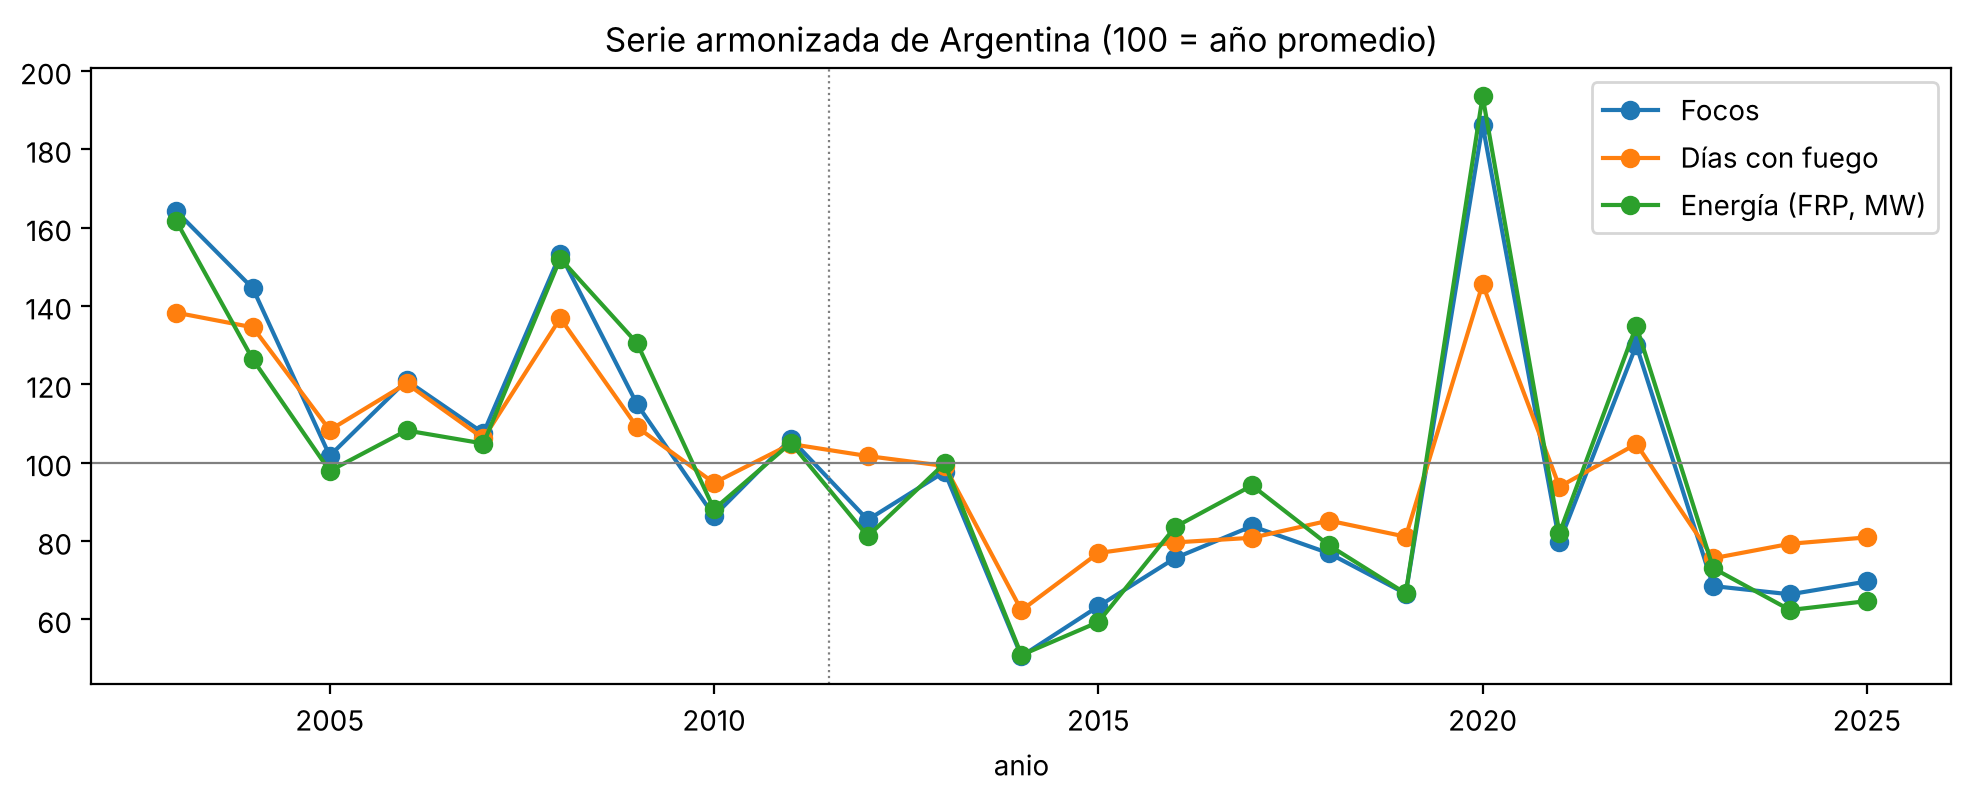

Correlación entre las tres medidas (años 2003–2025):


,Focos,Días con fuego,"Energía (FRP, MW)"
Focos,1.00,0.96,0.98
Días con fuego,0.96,1.00,0.92
"Energía (FRP, MW)",0.98,0.92,1.00


Los 5 años más activos según cada medida:


,Focos,Días con fuego,"Energía (FRP, MW)"
0,2020,2020,2020
1,2003,2003,2003
2,2008,2008,2008
3,2004,2004,2022
4,2022,2006,2009


In [16]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
final = {}
for m, t in tablas.items():
    ajustar, predecir = METODOS[elegido[m]]
    modelo = ajustar(datos_par(t))
    t = t.copy()
    t["estimado"] = np.nan
    con_dato = t.modis.notna()
    t.loc[con_dato, "estimado"] = predecir(modelo, t[con_dato])
    t["equiv"] = np.where(t.anio >= ANIO_INICIO_VIIRS, t.viirs + t.relleno, t.estimado)
    final[m] = t

indice_anual = pd.DataFrame({NOMBRE_MEDIDA[m]: t[t.anio <= 2025].groupby("anio").equiv.sum() for m, t in final.items()})
indice_anual = 100 * indice_anual / indice_anual.mean()

ax = indice_anual.plot(figsize=(12, 4), marker="o")
ax.axhline(100, color="gray", lw=.8); ax.axvline(2011.5, color="gray", ls=":", lw=.8)
ax.set_title("Serie armonizada de Argentina (100 = año promedio)"); plt.show()

print("Correlación entre las tres medidas (años 2003–2025):")
display(indice_anual.corr().round(3))
print("Los 5 años más activos según cada medida:")
display(pd.DataFrame({c: indice_anual[c].nlargest(5).index.values for c in indice_anual}))

## 11. Serie final y archivos para la página web

Se guardan en Drive, en **Challenge NASA 2026 / salida**:
- `serie_armonizada.csv`: región × año × mes, con las tres medidas. Por cada medida: MODIS, VIIRS observado,
  **relleno** de los días sin dato y armonizado (`_equiv`). La columna `dias_sin_dato` dice cuántos días se rellenaron.
- `grilla_mensual.csv`: celdas de ~25 km para el mapa (focos armonizados con el factor de cada región)
- `dias_sin_dato.csv`: la lista de días sin dato de cada satélite y con qué se rellenó
- `regiones.json`, `metricas.json`: regiones, comparación de métodos, justificación, validación, fechas de cada satélite
- `versiones.json`: versiones de Python y de las librerías usadas
- carpeta `focos/`: los focos individuales, un archivo por año. Incluye los focos de NOAA-20 **solo** en los días sin dato
  de S-NPP, marcados con `relleno = True`.

Esos archivos se copian a la carpeta `datos/` de la página web.

In [17]:
# Code written with assistance from Claude (Anthropic, a Super Intelligence tool); reviewed by the team.
# ---- serie armonizada
serie = None
for m, t in final.items():
    parte = t[["region", "anio", "mes", "modis", "viirs", "relleno", "equiv"]].rename(
        columns={c: f"{m}_{c}" for c in ["modis", "viirs", "relleno", "equiv"]})
    serie = parte if serie is None else serie.merge(parte, on=["region", "anio", "mes"])
serie = serie.merge(tablas["focos"][["region", "anio", "mes", "dias_sin_dato"]], on=["region", "anio", "mes"])
cols_medida = [f"{m}_{c}" for m in MEDIDAS for c in ["modis", "viirs", "relleno", "equiv"]]
pais = (serie.groupby(["anio", "mes"])[cols_medida].sum(min_count=1)
        .join(serie.groupby(["anio", "mes"]).dias_sin_dato.first()).reset_index().assign(region=PAIS))
serie = pd.concat([pais, serie], ignore_index=True)[["region", "anio", "mes"] + cols_medida + ["dias_sin_dato"]]
serie["fuente"] = np.where(serie.anio >= ANIO_INICIO_VIIRS, "VIIRS", "MODIS armonizado")
serie = serie.round(2)

# ---- grilla del mapa: VIIRS observado + NOAA-20 calibrado en los días sin dato; antes de 2012, MODIS × factor
factores = factor_region(datos_par(tablas["focos"]), "viirs", "modis")
g = grilla.pivot_table(index=["lat_c", "lon_c", "region", "anio", "mes"], columns="sensor",
                       values="focos", fill_value=0).reset_index()
if HAY_N20:
    dias_rellenar = nac.index[sin_dato_viirs & activo.n20 & ~huecos.n20]
    cn = pd.concat(partes["celdadia_n20"])
    cn = cn[cn.fecha.isin(dias_rellenar)]
    cn = (cn.assign(anio=cn.fecha.dt.year, mes=cn.fecha.dt.month, n20=cn.focos * cn.region.map(K_N20["focos"]))
          .groupby(["lat_c", "lon_c", "region", "anio", "mes"], as_index=False).n20.sum())
    g = g.merge(cn, on=["lat_c", "lon_c", "region", "anio", "mes"], how="outer").fillna(0)
else:
    g["n20"] = 0.0
chequear_regiones(g, factores)
g["focos_equiv"] = np.where(g.anio >= ANIO_INICIO_VIIRS, g.viirs + g.n20, g.modis * g.region.map(factores))
grilla_final = g[g.focos_equiv > 0][["lat_c", "lon_c", "region", "anio", "mes", "focos_equiv"]].round(2)

# ---- lista de días sin dato
lista = []
for f in ["viirs", "n20", "modis"]:
    for dia in nac.index[huecos[f]]:
        con = "—"
        if f == "viirs":
            con = "NOAA-20" if (HAY_N20 and activo.n20[dia] and not huecos.n20[dia]) else "MODIS convertido"
        lista.append({"fecha": dia.date(), "satelite": NOMBRE_FUENTE[f], "focos_observados": int(nac.loc[dia, f]),
                      "focos_esperados": round(float(esperado[f][nac.index.get_loc(dia)]), 1), "relleno_con": con})
dias_sin_dato = pd.DataFrame(lista)

# ---- métricas
ta_ = (terra_aqua.get("Terra") / terra_aqua.get("Aqua")).round(3)
pares = datos_par(tablas["focos"])
metricas = {
    "fecha_fin": f"{FECHA_FIN:%Y-%m-%d}",
    "fechas_sensor": FECHAS_SENSOR,
    "anios_entrenamiento": f"{ANIOS_ENTRENAMIENTO[0]}–{ANIOS_ENTRENAMIENTO[-1]}",
    "anios_test": f"{ANIOS_TEST[0]}–{ANIOS_TEST[-1]}",
    "tolerancia": TOLERANCIA,
    "regla": REGLA,
    "nombres": NOMBRE_MEDIDA,
    "elegido": elegido,
    "justificacion": justificacion,
    "resultados": {m: r.drop(columns=["MAE IC95 bajo", "MAE IC95 alto"]).reset_index().to_dict(orient="records")
                   for m, r in resultados.items()},
    "intervalos_mae": intervalos,
    "antes_despues": antes_despues.to_dict(orient="records"),
    "anual_test": {m: d.rename_axis("anio").reset_index().to_dict(orient="list") for m, d in anual_test.items()},
    "factores_focos": {k: round(v, 3) for k, v in factores.items()},
    "indice_anual": indice_anual.round(1).reset_index().to_dict(orient="list"),
    "correlacion_medidas": indice_anual.corr().round(3).to_dict(),
    "terra_sobre_aqua": {int(k): v for k, v in ta_.dropna().items()},
    "factor_pais_focos": round(float(pares.viirs.sum() / pares.modis.sum()), 3),
    "dias_sin_dato": {NOMBRE_FUENTE[f]: int(huecos[f].sum()) for f in ["viirs", "n20", "modis"]},
    "regla_dias_sin_dato": f"observado < {UMBRAL_HUECO:.0%} de lo esperado según los otros satélites, con ≥ {MIN_ESPERADO} focos esperados",
    "n20_factor": K_N20,
    "n20_validacion": validacion_n20.round(4).reset_index().to_dict(orient="records") if HAY_N20 else None,
    "embudo": emb.reset_index().rename(columns={"index": "fuente"}).to_dict(orient="records"),
    "archivos_con_problemas": fallidos,
}

def a_json(o):   # punto 24: tipos de numpy y fechas
    if isinstance(o, (np.integer, np.floating, np.bool_)):
        return o.item()
    return str(o)

# ---- focos individuales: MODIS + S-NPP, y NOAA-20 solo en los días sin dato de S-NPP
puntos["relleno"] = False
if HAY_N20:
    pn = pd.concat(partes["puntos_n20"], ignore_index=True)
    pn = pn[pd.to_datetime(pn.fecha).isin(dias_rellenar)].assign(relleno=True)
    puntos_todos = pd.concat([puntos, pn], ignore_index=True)
else:
    puntos_todos = puntos
puntos_todos["fecha"] = pd.to_datetime(puntos_todos.fecha)
for c in ["sensor", "satelite", "confianza", "region"]:
    puntos_todos[c] = puntos_todos[c].astype("category")

serie.to_csv(os.path.join(CARPETA_SALIDA, "serie_armonizada.csv"), index=False)
grilla_final.to_csv(os.path.join(CARPETA_SALIDA, "grilla_mensual.csv"), index=False)
dias_sin_dato.to_csv(os.path.join(CARPETA_SALIDA, "dias_sin_dato.csv"), index=False)
carpeta_focos = os.path.join(CARPETA_SALIDA, "focos")
shutil.rmtree(carpeta_focos, ignore_errors=True); os.makedirs(carpeta_focos)
for a_, sub in puntos_todos.groupby(puntos_todos.fecha.dt.year):
    sub.sort_values(["fecha", "hora_utc"]).to_parquet(
        os.path.join(carpeta_focos, f"focos_{a_}.parquet"), index=False, compression="zstd")
print(f"Focos individuales guardados: {len(puntos_todos):,} ({puntos_todos.relleno.sum():,} de NOAA-20 en días sin dato)")
with open(os.path.join(CARPETA_SALIDA, "regiones.json"), "w", encoding="utf-8") as f:
    json.dump(REGIONES, f, ensure_ascii=False, indent=2)
with open(os.path.join(CARPETA_SALIDA, "metricas.json"), "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2, default=a_json)
with open(os.path.join(CARPETA_SALIDA, "versiones.json"), "w", encoding="utf-8") as f:
    json.dump(VERSIONES, f, indent=2)

for f in sorted(os.listdir(CARPETA_SALIDA)):
    ruta = os.path.join(CARPETA_SALIDA, f)
    tam = (sum(os.path.getsize(os.path.join(ruta, x)) for x in os.listdir(ruta)) if os.path.isdir(ruta)
           else os.path.getsize(ruta))
    print(f"{f:25s} {tam / 1e6:6.2f} MB")

if EN_COLAB:
    destino = os.path.join(RUTA_DRIVE, SUBCARPETA_SALIDA)
    os.makedirs(destino, exist_ok=True)
    shutil.copytree(CARPETA_SALIDA, destino, dirs_exist_ok=True)
    print(f"\nGuardado en Drive: Mi unidad/{CARPETA_DRIVE}/{SUBCARPETA_SALIDA}")

Focos individuales guardados: 4,145,140 (23,723 de NOAA-20 en días sin dato)
dias_sin_dato.csv           0.00 MB
focos                      49.90 MB
grilla_mensual.csv         10.78 MB
metricas.json               0.02 MB
regiones.json               0.00 MB
serie_armonizada.csv        0.20 MB
versiones.json              0.00 MB
